<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/27_QML_Privacy_Data_Leakage/VQC_Unlearning_Masud2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# VQC machine unlearning with SQU (Sensitivity-Guided Quantum Unlearning): Masud et al. (2026) step by step

This notebook re-implements, runs and checks the experiments of

> Md Akmol Masud, Zannat Hossain Tamim, Md Musa Kalimullah Ratul and Md Biplob Hosen,
> "SQU: Sensitivity-Guided Quantum Machine Unlearning for Privacy-Preserving ML",
> 2026 IEEE 2nd International Conference on Quantum Photonics, Artificial Intelligence, and Networking (QPAIN), Chittagong, 16-18 April 2026.
> DOI: https://doi.org/10.1109/QPAIN69676.2026.11546660
> Authors' code: https://github.com/masud1901/Sensitivity-Guided-Quantum-Machine-Unlearning (pinned here at commit `8391bd4e8728f4b9ecb2ea201f7bd4a099c09ce6`).

**The story in five sentences.** Privacy laws such as the GDPR give people a "right to be forgotten": if somebody asks, their record must stop influencing a trained model.
Retraining from scratch always works but is expensive, so *machine unlearning* looks for cheaper ways. The paper proposes SQU for a small variational quantum classifier (VQC):
measure how strongly each sample to be forgotten pulls on the circuit parameters (the gradient norm), give strongly-pulling samples a bigger noise budget, add Gaussian noise to the
parameters and then fine-tune on the data that is kept. A membership inference attack (MIA: "was this sample in the training set?") is the privacy yardstick, and
"retrain from scratch" is the gold standard that SQU should match. The notebook redraws the paper's Table III, Table IV and Figs. 4 and 5 and checks every number.

**What the notebook does.**
1. Loads three public datasets: Breast Cancer Wisconsin (scikit-learn), MNIST (digits 0 vs 1) and Fashion-MNIST (T-shirt vs trouser), exactly the binary tasks of the authors' code.
2. Draws the real data (class distributions, 2-D projections coloured by the true label, example images).
3. Writes the 4-qubit circuit as a fast exact PyTorch simulator and **asserts it equals the PennyLane QNode** (values and gradients), draws the executed circuit, and cross-checks it against the authors' own `QuantumClassifier` when `git` is available.
4. Trains the VQC (plain gradient descent, MSE, 20 epochs), the classical neural network, and runs five unlearning treatments: SQU (two readings: the authors' code and the paper's Eq. 5), static noise, simple noise, gradient ascent, plus the retrain-from-scratch gold standard.
5. **Replays the authors' own run** (seed 42, their random-number order) with the verified simulator: Breast Cancer, MNIST and Fashion-MNIST come out as in the paper's Table III and Fig. 4. Then it repeats everything over many random seeds (the paper reports one run), prints the paper's numbers next to both with a verdict per claim, and reads the paper critically.

**How to run.** Colab, CPU runtime, *Runtime -> Run all*. The committed notebook was executed with `FAST_MODE = False` (20 seeds, 62 minutes on a busy shared CPU core); `FAST_MODE = True` uses 5 seeds (about 15 minutes). The budgets are in the configuration cell. No GPU, no quantum hardware and no account are needed. All three datasets are public;
if a Hugging Face mirror ever asks for a login, put your own token in Colab *Secrets* under the name `HF_TOKEN` (it is read only from the environment or Colab Secrets, never from the code).

**What you get at the end.** A table of the paper's numbers next to ours with a verdict per number, the circuit drawing, the loss curves, the accuracy / MIA bar charts with error bars,
and a critical reading that includes one structural finding about the circuit (only 3 of its 12 parameters can matter, proved numerically in the circuit section).

## The paper in one page

**Problem.** After a VQC has been trained on a dataset D, a few training samples D_f ("forget set") must be removed so that the model behaves as if it had been trained on D_r = D \ D_f only.
The yardstick for "forgotten" is the membership inference attack (MIA): an adversary scores the model's confidence on a sample and tries to tell training samples from unseen samples.
The AUC of this attacker is reported as `max(AUC, 1 - AUC)` (0.5 = random guessing, 1.0 = complete leakage).

**Model (Fig. 1, Eqs. 1-3).** 4 qubits, 1 layer. Angle encoding `RY(x_j)` on every qubit, a general rotation `RZ-RY-RZ` (PennyLane `Rot`) on every qubit (12 trainable angles), a chain of CNOTs
between neighbouring qubits, and the Pauli-Z expectation value of the first qubit as the output f(x; theta) in [-1, 1]; predicted label = sign(f).

**SQU (Algorithm 1).** (1) Sensitivity S_k = ||grad_theta loss(x_k, y_k)||_2 of every forget sample. (2) Budget allocation: tiers High (S > mu + sigma), Medium, Low and a noise scale proportional to S
(Eq. 5: sigma_k = (1/eps) * S_k / max_j S_j). (3) Inject Gaussian noise N(0, sigma_k^2 I) into the parameters, once per forget sample, **before** (4) a short fine-tuning on the retain set.

**Data and protocol (Table II).** Breast Cancer: 300 samples, 70/30 split (210 / 90), a few samples forgotten, min-max scaling and PCA to 4 dimensions; 20 epochs, learning rate 0.01, batch 10; SQU fine-tuning 10 epochs; eps = 1.
MNIST and Fashion-MNIST are used as binary tasks (the authors' code: 0 vs 1 and T-shirt vs trouser). Baselines: No Unlearning, Static Unlearning (uniform noise), Simple Noise, Gradient Ascent, Retrain from Scratch, and a classical neural network.

**Claims to check.**
(i) Table III: SQU accuracy 83.3 / 97.9 / 79.2 % and retrain 84.4 / 97.9 / 79.2 % on Breast Cancer / MNIST / Fashion-MNIST; MIA AUC of SQU 0.648 / 0.530 / 0.609 and of retrain 0.654 / 0.527 / 0.608.
(ii) Privacy gain (MIA AUC reduction, in AUC points x 100): SQU +0.67 / 0.00 / -0.08, static +0.07 / -7.19 / -1.61.
(iii) Fig. 5 and Table IV: the 12-parameter VQC reaches 84.4 % (final loss about 0.36, plateau around epoch 15); the classical NN (about 2,498 parameters) reaches 94.4 % (loss 0.14); MIA AUC before unlearning 0.654 (VQC) versus 0.555 (NN).
(iv) Fig. 4c: the forget-sample sensitivities are non-uniform (4 high / 4 medium / 7 low on Breast Cancer, i.e. 15 forget samples).
(v) Qualitative: SQU matches retraining in accuracy, never degrades privacy as static noise does, and "exact sensitivity analysis is feasible" because the VQC has only 12 parameters.

### What follows the paper and what had to be chosen

The authors' public code settles most of what the paper leaves open; it is used where the paper is silent and the two disagree in a few places (marked **differs**).

| Item | Paper | This notebook |
|---|---|---|
| Qubits / layers / readout | 4 / 1 / Z on qubit 0 | same |
| Encoding | `RY(x_j)` per qubit, Eq. 1 | same; features scaled to [-pi/2, pi/2] (authors' code); `# CHOICE` min and max are taken from the **training** PCA coordinates only and test angles are clipped |
| Ansatz | `RZ-RY-RZ` general rotation + CNOT chain (Fig. 1, Eq. 2) | `qml.Rot` on every qubit, then CNOT(0,1), CNOT(1,2), CNOT(2,3) (authors' code). Eq. 2 can be read as "CNOTs first"; the figure and the code put them after the rotations (`# CHOICE`: follow the code). Initial angles uniform in [0, 1) as in the code |
| Loss, optimiser | not stated | mean squared error between f(x) and the label in {-1, +1}; plain gradient descent, lr 0.01, batch 10, 20 epochs (authors' code, Table II) |
| Prediction | sign(f) | class 1 if f > 0 (authors' code) |
| Datasets | Breast Cancer; MNIST; Fashion-MNIST | Breast Cancer (300 random of 569); MNIST **0 vs 1** and Fashion-MNIST **T-shirt vs trouser**, 800 random images each (authors' code; the paper never says the tasks are binary) |
| Split | 70 / 30 | stratified 70 / 30, `random_state` = seed |
| Pre-processing | "min-max scaling, PCA to 4-D" | `StandardScaler` then `PCA(4)` (authors' code uses standardisation, not min-max); **both fitted on the training split only** (the authors' code fits them on all samples before splitting, which leaks test information; `# CHOICE`, deviation from the code) |
| Number of forgotten samples | **differs**: Table II says 10 (and 200 retained of 210); Fig. 4c shows 15 (4+4+7) and the code uses 15 | 15 for all tables (`N_FORGET`); an extra Breast Cancer run with 10 is reported as a robustness row |
| SQU noise, "code" reading | not given in this form | per forget sample: normalised sensitivity s_i (min-max over the forget set), budget_i = eps * s_i / sum(s), noise scale = budget_i * {0.5, 0.35, 0.2} for High (s > 0.7), Medium (s > 0.3), Low; the noise is added to all 12 angles, then 5 fine-tuning epochs on D_r (authors' code) |
| SQU noise, "paper" reading | Eq. 5: sigma_k = S_k / (eps max S), Eq. 6 aggregated variance, 10 fine-tuning epochs (Table II) | implemented literally and reported as a second SQU row (`squ_paper`) |
| Tiers in the figure | High if S > mu + sigma (Alg. 1) | both rules are computed; the figure uses the code's normalised thresholds 0.7 / 0.3 because they match Fig. 4c's 4 / 4 / 7 |
| Static unlearning | "uniform noise" | per forget sample N(0, (eps/n * 0.35)^2) on every angle, no fine-tuning (authors' code) |
| Simple noise | "random Gaussian" | one N(0, 0.3^2) injection, no fine-tuning (authors' code) |
| Gradient ascent | not specified | 5 ascent steps, lr 0.01, on the mean squared error of the forget set (authors' code) |
| Retrain from scratch | on D_r only | new random initialisation, 20 epochs on D_r |
| MIA | confidence AUC, `max(AUC, 1-AUC)` | score = |f(x)| of the forget samples (members) versus all test samples (non-members), as in the authors' code; classical NN: max softmax probability |
| Classical NN | two hidden layers (64, 32), ReLU, dropout; "same PCA-reduced data", about 2,498 parameters, 20 epochs | same architecture (Adam, lr 1e-3, batch 32, dropout 0.2). Run on **both** the 4 PCA angles (paper text; 2,466 parameters) and on all standardised features (authors' `run_classical.py`; 4,130 parameters on Breast Cancer) for 20 epochs (paper) and 50 epochs (code) |
| Seeds | one run (the numbers are multiples of 1/90 and 1/240, i.e. one split) | (1) a **replay of the authors' run** (their `np.random.seed(42)` stream and leaky pre-processing, simulator instead of their PennyLane loop); (2) `N_SEEDS` independent runs (data draw, split, forget set, initialisation) with train-only pre-processing, mean +- std |
| Simulator | TFQ + PennyLane (Table II) | exact PyTorch state-vector simulator, asserted equal to the PennyLane QNode and to the authors' class; TensorFlow Quantum is not used (the code is PennyLane only) |
| Hardware / noise | noiseless simulation (Section VI) | noiseless simulation |

## 0. Setup

In [1]:
# Pinned installs: Colab already ships numpy, pandas, scikit-learn, matplotlib and torch; PennyLane is the only extra.
import importlib, subprocess, sys
try:
    IN_COLAB = "google.colab" in sys.modules
except Exception:
    IN_COLAB = False
try:
    import pennylane  # noqa: F401
    NEED_INSTALL = IN_COLAB and pennylane.__version__ != "0.45.1"
except Exception:
    NEED_INSTALL = True
if NEED_INSTALL:
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "pennylane==0.45.1", "pylatexenc"], check=False)
    print("Installed pennylane==0.45.1 (if Colab asks, restart the runtime once and Run all again).")
else:
    print("PennyLane already available; nothing to install.")

PennyLane already available; nothing to install.


### Configuration

Every tunable constant is in the next cell. The committed notebook was executed with the `FAST_MODE` value printed in the first output line of this cell. `IBM_TOKEN` is unused: the paper
uses a noiseless simulator only (Section VI says device noise is future work).

In [2]:
# ---------------------------------------------------------------------------------------------
# CONFIGURATION: every tunable constant lives in this cell.
# ---------------------------------------------------------------------------------------------
import os
FAST_MODE = False            # True: 5 seeds (a few minutes); False: 20 seeds (about 60 min on a busy shared CPU core)
SEED = 42                   # master seed; run r uses SEED + r
DATA_DIR = os.environ.get("SQU_DATA_DIR", "squ_data")   # cache for MNIST / Fashion-MNIST (downloaded automatically)
IBM_TOKEN = ""              # unused: noiseless simulation only (paper, Section VI)
USE_AUTHOR_REPO = True      # clone the authors' repo to cross-check our simulator against their QuantumClassifier
RUN_AUTHOR_CODE = False     # True: also run the authors' own run_experiments.py for Breast Cancer (about 10 min) and print its numbers
REPO_URL = "https://github.com/masud1901/Sensitivity-Guided-Quantum-Machine-Unlearning.git"
REPO_COMMIT = "8391bd4e8728f4b9ecb2ea201f7bd4a099c09ce6"

# --- data (paper Table II; authors' config.py) ---
DATASETS = ("breast_cancer", "mnist", "fashion_mnist")
N_SAMPLES = dict(breast_cancer=300, mnist=800, fashion_mnist=800)   # random subsample per run (authors: MAX_SAMPLES=300; n_samples=800 for the image sets)
TEST_SIZE = 0.3
N_FORGET = 15               # CHOICE: paper Table II says 10, Fig. 4c and the authors' code use 15
N_FORGET_ALT = 10           # extra robustness run on Breast Cancer with the Table II value

# --- circuit and training (paper Table II; authors' config.py) ---
N_QUBITS, N_LAYERS = 4, 1
LR, BATCH, EPOCHS = 0.01, 10, 20
EPSILON = 1.0               # total privacy budget
FT_EPOCHS_CODE = 5          # SQU fine-tuning epochs in the authors' code
FT_EPOCHS_PAPER = 10        # SQU fine-tuning epochs in Table II ("SQU retraining epochs 10")

# --- SQU tiers and noise levels (authors' config.py) ---
TIER_HIGH, TIER_MED = 0.7, 0.3                # thresholds on min-max normalised sensitivity
NOISE_HIGH, NOISE_MED, NOISE_LOW = 0.5, 0.35, 0.2
GA_STEPS, GA_LR = 5, 0.01                     # gradient-ascent baseline
SIMPLE_STD = 0.3 * EPSILON                    # simple-noise baseline: one N(0, (0.3 eps)^2) injection

# --- classical NN baseline ---
NN_EPOCHS = (20, 50)        # paper text (20) and authors' run_classical.py (50)

# --- how many independent runs (paper: a single run) ---
N_SEEDS = 5 if FAST_MODE else 20
print(dict(FAST_MODE=FAST_MODE, N_SEEDS=N_SEEDS, N_FORGET=N_FORGET, EPOCHS=EPOCHS, LR=LR, BATCH=BATCH))

{'FAST_MODE': False, 'N_SEEDS': 20, 'N_FORGET': 15, 'EPOCHS': 20, 'LR': 0.01, 'BATCH': 10}


In [3]:
import io, gzip, time, copy, json, warnings, subprocess
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import pennylane as qml
import sklearn
from sklearn.datasets import load_breast_cancer
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score
from scipy import stats
warnings.filterwarnings("ignore")
torch.set_default_dtype(torch.float64)
torch.set_num_threads(1)
os.makedirs(DATA_DIR, exist_ok=True)
rng_master = np.random.default_rng(SEED)
np.random.seed(SEED); torch.manual_seed(SEED)
print("numpy", np.__version__, "| pandas", pd.__version__, "| sklearn", sklearn.__version__, "| matplotlib", matplotlib.__version__)
print("torch", torch.__version__, "| pennylane", qml.__version__)

# Hugging Face token: only used as a fallback mirror for MNIST / Fashion-MNIST, read only from the environment or Colab Secrets.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

numpy 2.5.4 | pandas 3.0.6 | sklearn 1.9.1 | matplotlib 3.11.2
torch 2.14.1+cpu | pennylane 0.45.1


## 1. Data: Breast Cancer, MNIST (0 vs 1), Fashion-MNIST (T-shirt vs trouser)

* **Breast Cancer Wisconsin (Diagnostic)** ships with scikit-learn: 569 patients, 30 numeric features computed from a digitised image of a fine-needle aspirate; label 0 = malignant, 1 = benign.
* **MNIST** and **Fashion-MNIST** are downloaded from public mirrors (Keras storage bucket; Hugging Face parquet as a fallback) and reduced to the two classes the authors' code uses
  (digits 0 vs 1; T-shirt/top = 0 vs trouser = 1). Only the two-class subset is cached in `DATA_DIR`; the original archives are deleted right after reading to save disk space.

Each run `r` draws its own random subsample (300 Breast Cancer samples, 800 images), splits it 70/30 with stratification, and chooses the forget set. Everything that is learned from data
(standardiser, PCA, angle scaling) is fitted on the training split only.

In [4]:
KERAS = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/"
CLASS_NAMES = dict(breast_cancer={0: "malignant", 1: "benign"}, mnist={0: "digit 0", 1: "digit 1"},
                   fashion_mnist={0: "T-shirt/top", 1: "trouser"})

def _download(url, dest):
    import requests
    r = requests.get(url, timeout=180); r.raise_for_status()
    with open(dest, "wb") as f:
        f.write(r.content)

def _hf_images(repo, files):
    """Fallback: Hugging Face parquet files with PNG bytes (public datasets; token only used if present)."""
    from huggingface_hub import hf_hub_download
    from PIL import Image
    X, y = [], []
    for fn in files:
        p = hf_hub_download(repo, fn, repo_type="dataset", cache_dir=os.path.join(DATA_DIR, "hf"), token=HF_TOKEN)
        df = pd.read_parquet(p)
        X.append(np.stack([np.array(Image.open(io.BytesIO(d["bytes"]))) for d in df["image"]]))
        y.append(df["label"].values.astype(np.uint8))
    return np.concatenate(X), np.concatenate(y)

def _idx(data):   # IDX (ubyte) parser used for Fashion-MNIST
    raw = gzip.decompress(data)
    if raw[2] == 8 and raw[3] == 3:
        n, h, w = (int.from_bytes(raw[4 + 4 * k:8 + 4 * k], "big") for k in range(3))
        return np.frombuffer(raw, np.uint8, offset=16).reshape(n, h, w)
    return np.frombuffer(raw, np.uint8, offset=8)

def load_binary_images(name):
    """Return (X uint8 [N,784], y in {0,1}) for MNIST 0-vs-1 or Fashion-MNIST T-shirt-vs-trouser; cached as a small .npz."""
    cache = os.path.join(DATA_DIR, f"{name}_01.npz")
    if not os.path.exists(cache):
        try:
            if name == "mnist":
                tmp = os.path.join(DATA_DIR, "mnist_full.npz"); _download(KERAS + "mnist.npz", tmp)
                d = np.load(tmp); X = np.concatenate([d["x_train"], d["x_test"]]); y = np.concatenate([d["y_train"], d["y_test"]]); del d
            else:
                parts = {}
                for k in ["train-images-idx3-ubyte.gz", "train-labels-idx1-ubyte.gz", "t10k-images-idx3-ubyte.gz", "t10k-labels-idx1-ubyte.gz"]:
                    tmp = os.path.join(DATA_DIR, "fashion_" + k); _download(KERAS + k, tmp)
                    parts[k] = _idx(open(tmp, "rb").read()); os.remove(tmp)
                X = np.concatenate([parts["train-images-idx3-ubyte.gz"], parts["t10k-images-idx3-ubyte.gz"]])
                y = np.concatenate([parts["train-labels-idx1-ubyte.gz"], parts["t10k-labels-idx1-ubyte.gz"]])
            source = "keras mirror"
        except Exception as e:
            print(f"{name}: primary mirror failed ({type(e).__name__}), using Hugging Face parquet")
            repo, folder = ("ylecun/mnist", "mnist") if name == "mnist" else ("zalando-datasets/fashion_mnist", "fashion_mnist")
            X, y = _hf_images(repo, [f"{folder}/train-00000-of-00001.parquet", f"{folder}/test-00000-of-00001.parquet"])
            source = "hugging face"
        for t in ("mnist_full.npz",):
            if os.path.exists(os.path.join(DATA_DIR, t)): os.remove(os.path.join(DATA_DIR, t))
        m = (y == 0) | (y == 1)
        np.savez_compressed(cache, X=X[m].reshape(m.sum(), -1).astype(np.uint8), y=y[m].astype(np.uint8), full_counts=np.bincount(y, minlength=10), source=source)
    d = np.load(cache)
    return d["X"], d["y"].astype(int), d["full_counts"]

POOL, FEATURES, FULL_COUNTS = {}, {}, {}
bc = load_breast_cancer()
POOL["breast_cancer"] = (bc.data, bc.target); FEATURES["breast_cancer"] = list(bc.feature_names)
for nm in ("mnist", "fashion_mnist"):
    Xp, yp, fc = load_binary_images(nm)
    POOL[nm] = (Xp, yp); FEATURES[nm] = [f"pixel_{i}" for i in range(784)]; FULL_COUNTS[nm] = fc
for nm, (Xp, yp) in POOL.items():
    print(f"{nm:14s}: pool X {Xp.shape}, y {yp.shape}, classes {dict(zip(*np.unique(yp, return_counts=True)))}")

breast_cancer : pool X (569, 30), y (569,), classes {np.int64(0): np.int64(212), np.int64(1): np.int64(357)}
mnist         : pool X (14780, 784), y (14780,), classes {np.int64(0): np.int64(6903), np.int64(1): np.int64(7877)}
fashion_mnist : pool X (14000, 784), y (14000,), classes {np.int64(0): np.int64(7000), np.int64(1): np.int64(7000)}


In [5]:
def prepare(name, seed):
    """Everything random in one run: which samples, the stratified 70/30 split, standardiser + PCA(4) + angle scaling fitted on the TRAIN split only."""
    rng = np.random.default_rng(seed)
    X, y = POOL[name]
    sel = rng.choice(len(X), min(N_SAMPLES[name], len(X)), replace=False)
    Xs, ys = X[sel].astype(float), y[sel]
    idx_tr, idx_te = train_test_split(np.arange(len(Xs)), test_size=TEST_SIZE, random_state=seed, stratify=ys)
    Xtr, Xte, ytr, yte = Xs[idx_tr], Xs[idx_te], ys[idx_tr], ys[idx_te]
    sc = StandardScaler().fit(Xtr)
    Str, Ste = sc.transform(Xtr), sc.transform(Xte)
    pca = PCA(n_components=N_QUBITS, random_state=seed).fit(Str)
    Ztr, Zte = pca.transform(Str), pca.transform(Ste)
    lo, hi = Ztr.min(), Ztr.max()           # CHOICE: one global min and max over the 4 training PCA coordinates (authors' code), train only
    ang = lambda Z: np.clip(np.pi * (Z - lo) / (hi - lo + 1e-8) - np.pi / 2, -np.pi / 2, np.pi / 2)
    return dict(name=name, seed=seed, Xtr=Xtr, Xte=Xte, ytr=ytr, yte=yte, Str=Str, Ste=Ste, Ztr=Ztr, Zte=Zte,
                Atr=ang(Ztr), Ate=ang(Zte), pca=pca, sel=sel, idx_tr=idx_tr, idx_te=idx_te)

D0 = {nm: prepare(nm, SEED) for nm in DATASETS}      # run 0 of every dataset, used for the exploration section
print({nm: (d["Xtr"].shape, d["Xte"].shape) for nm, d in D0.items()})

{'breast_cancer': ((210, 30), (90, 30)), 'mnist': ((560, 784), (240, 784)), 'fashion_mnist': ((560, 784), (240, 784))}


## Dataset Exploration and Visualisation

Everything below is computed from the real observations of run 0 (seed 42); nothing is synthetic. For each of the three datasets we print the shape, the feature names, the original label values
and class counts, draw the real class distribution, and draw two-dimensional scatter plots in which **every point is a real observation coloured by its ground-truth label**:
first the raw PCA coordinates (PCA fitted on the training split), then the same coordinates scaled to the encoding angles [-pi/2, pi/2] that go into the `RY` gates
(star markers = the samples chosen to be forgotten). For the two image data sets a grid of real images is added. All three tasks are binary, so the colour is the class (there are no attack families here).

In [6]:
def describe(name):
    d = D0[name]; X, y = POOL[name]
    print("=" * 100)
    print(f"{name}: pool shape {X.shape} | sample drawn for this run: {len(d['sel'])} | train {d['Xtr'].shape} | test {d['Xte'].shape}")
    fn = FEATURES[name]
    print(f"features ({len(fn)}): " + (", ".join(fn) if len(fn) <= 30 else ", ".join(fn[:4]) + ", ..., " + ", ".join(fn[-2:])))
    print("model inputs: 4 PCA coordinates -> angles in [-pi/2, pi/2] (one feature per qubit)")
    cn = CLASS_NAMES[name]
    print("original label values and counts in the pool   :", {f"{k} ({cn[k]})": int(v) for k, v in zip(*np.unique(y, return_counts=True))})
    if name in FULL_COUNTS:
        print("  (full original dataset before keeping 2 classes: counts per label 0-9 =", FULL_COUNTS[name].tolist(), ")")
    print("class counts in this run's training split       :", {f"{k} ({cn[k]})": int(v) for k, v in zip(*np.unique(d["ytr"], return_counts=True))})
    print("class counts in this run's test split           :", {f"{k} ({cn[k]})": int(v) for k, v in zip(*np.unique(d["yte"], return_counts=True))})
for nm in DATASETS:
    describe(nm)

breast_cancer: pool shape (569, 30) | sample drawn for this run: 300 | train (210, 30) | test (90, 30)
features (30): mean radius, mean texture, mean perimeter, mean area, mean smoothness, mean compactness, mean concavity, mean concave points, mean symmetry, mean fractal dimension, radius error, texture error, perimeter error, area error, smoothness error, compactness error, concavity error, concave points error, symmetry error, fractal dimension error, worst radius, worst texture, worst perimeter, worst area, worst smoothness, worst compactness, worst concavity, worst concave points, worst symmetry, worst fractal dimension
model inputs: 4 PCA coordinates -> angles in [-pi/2, pi/2] (one feature per qubit)
original label values and counts in the pool   : {'0 (malignant)': 212, '1 (benign)': 357}
class counts in this run's training split       : {'0 (malignant)': 85, '1 (benign)': 125}
class counts in this run's test split           : {'0 (malignant)': 37, '1 (benign)': 53}
mnist: pool s

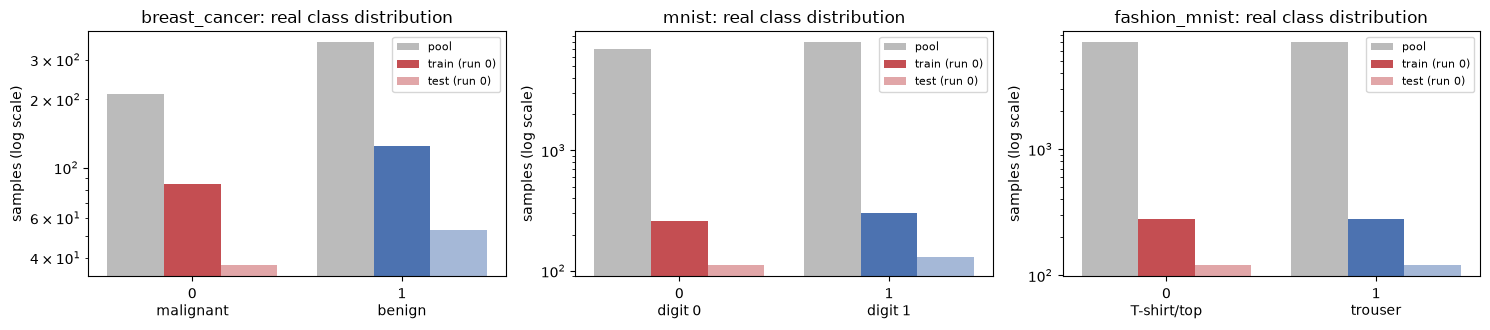

In [7]:
COL = {0: "#C44E52", 1: "#4C72B0"}
fig, axes = plt.subplots(1, 3, figsize=(15, 3.4))
for ax, nm in zip(axes, DATASETS):
    d = D0[nm]; cn = CLASS_NAMES[nm]
    X, y = POOL[nm]
    w = 0.27; ks = [0, 1]
    ax.bar(np.array(ks) - w, [int((y == k).sum()) for k in ks], w, color="#bbbbbb", label="pool")
    ax.bar(np.array(ks), [int((d["ytr"] == k).sum()) for k in ks], w, color=[COL[k] for k in ks], label="train (run 0)")
    ax.bar(np.array(ks) + w, [int((d["yte"] == k).sum()) for k in ks], w, color=[COL[k] for k in ks], alpha=0.5, label="test (run 0)")
    ax.set_xticks(ks); ax.set_xticklabels([f"{k}\n{cn[k]}" for k in ks]); ax.set_yscale("log")
    ax.set_title(f"{nm}: real class distribution"); ax.set_ylabel("samples (log scale)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

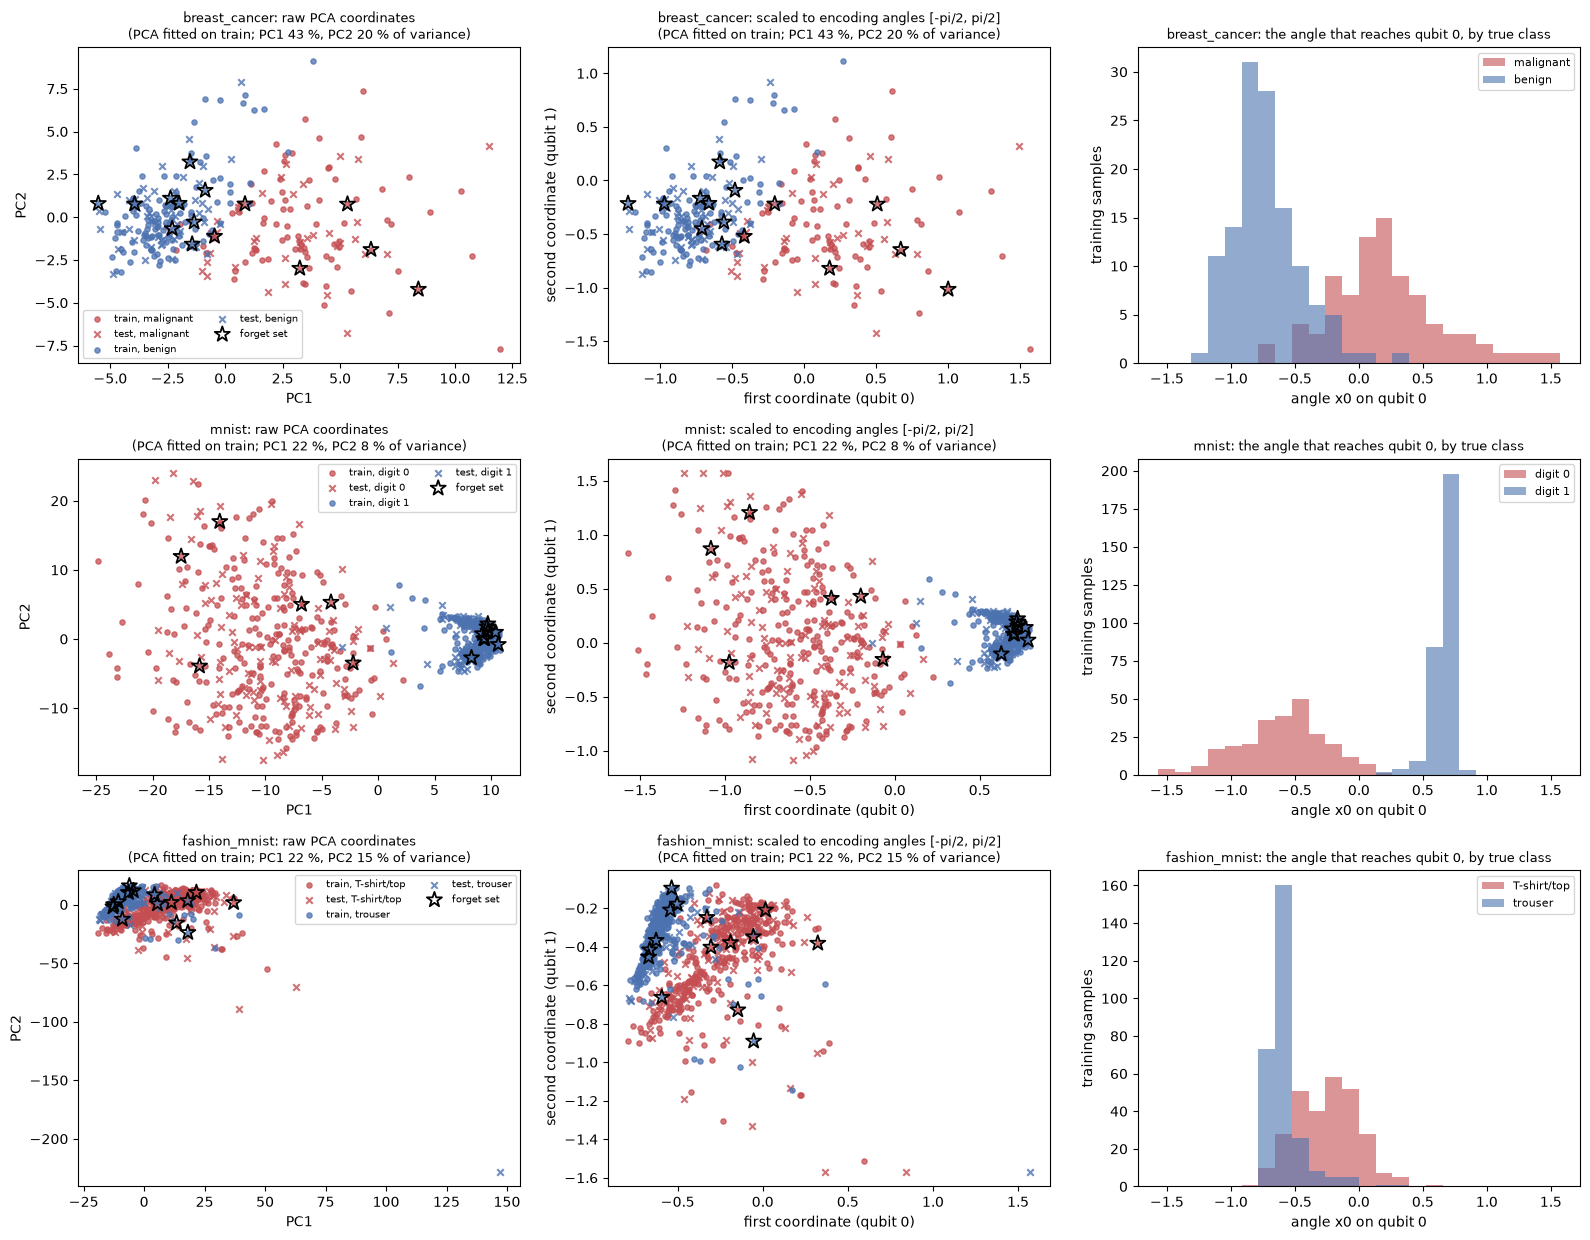

In [8]:
def forget_idx_for(d, n_forget, seed):
    return np.random.default_rng(seed + 10_000).choice(len(d["ytr"]), n_forget, replace=False)

fig, axes = plt.subplots(3, 3, figsize=(16, 12.5))
for r_, nm in enumerate(DATASETS):
    d = D0[nm]; cn = CLASS_NAMES[nm]; fi = forget_idx_for(d, N_FORGET, SEED)
    var = d["pca"].explained_variance_ratio_
    for c_, (Ztr, Zte, lab) in enumerate([(d["Ztr"], d["Zte"], "raw PCA coordinates"), (d["Atr"], d["Ate"], "scaled to encoding angles [-pi/2, pi/2]")]):
        ax = axes[r_, c_]
        for k in (0, 1):
            ax.scatter(Ztr[d["ytr"] == k, 0], Ztr[d["ytr"] == k, 1], s=14, color=COL[k], alpha=0.75, label=f"train, {cn[k]}")
            ax.scatter(Zte[d["yte"] == k, 0], Zte[d["yte"] == k, 1], s=22, marker="x", color=COL[k], alpha=0.8, label=f"test, {cn[k]}")
        ax.scatter(Ztr[fi, 0], Ztr[fi, 1], s=130, marker="*", facecolor="none", edgecolor="k", linewidth=1.3, label="forget set")
        ax.set_xlabel("first coordinate (qubit 0)" if c_ else "PC1"); ax.set_ylabel("second coordinate (qubit 1)" if c_ else "PC2")
        ax.set_title(f"{nm}: {lab}\n(PCA fitted on train; PC1 {100*var[0]:.0f} %, PC2 {100*var[1]:.0f} % of variance)", fontsize=9)
        if c_ == 0: ax.legend(fontsize=7, ncol=2)
    ax = axes[r_, 2]
    for k in (0, 1):
        ax.hist(d["Atr"][d["ytr"] == k, 0], bins=24, range=(-np.pi / 2, np.pi / 2), alpha=0.6, color=COL[k], label=cn[k])
    ax.set_xlabel("angle x0 on qubit 0"); ax.set_ylabel("training samples"); ax.legend(fontsize=8)
    ax.set_title(f"{nm}: the angle that reaches qubit 0, by true class", fontsize=9)
plt.tight_layout(); plt.show()

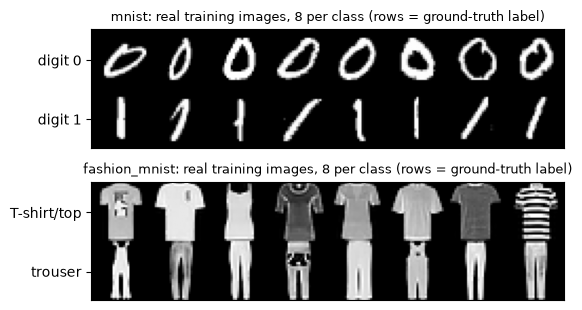

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(12, 3.2))
for ax, nm in zip(axes, ("mnist", "fashion_mnist")):
    d = D0[nm]; cn = CLASS_NAMES[nm]
    tiles = []
    for k in (0, 1):
        ids = np.where(d["ytr"] == k)[0][:8]
        tiles.append(np.concatenate([d["Xtr"][i].reshape(28, 28) for i in ids], axis=1))
    ax.imshow(np.concatenate(tiles, axis=0), cmap="gray"); ax.set_xticks([]); ax.set_yticks([14, 42]); ax.set_yticklabels([cn[0], cn[1]])
    ax.set_title(f"{nm}: real training images, 8 per class (rows = ground-truth label)", fontsize=9)
plt.tight_layout(); plt.show()

## 2. A fast exact simulator of the paper's 4-qubit VQC

Training the VQC, computing 15 per-sample gradients, running five unlearning treatments and repeating all of it for many seeds and three datasets means thousands of circuit evaluations with gradients.
PennyLane's `default.qubit` can do this but slowly in a Python loop. We therefore write the same circuit as a few batched tensor operations in PyTorch (exact state-vector simulation, differentiable)
and **assert in the next section that it agrees with the real PennyLane QNode, for outputs and for gradients**.

The circuit (paper Fig. 1, authors' `quantum_classifier.py`): `RY(x_j)` on each qubit j, then for each layer a `Rot(phi, theta, omega) = RZ(omega) RY(theta) RZ(phi)` on each qubit followed by
CNOT(0,1), CNOT(1,2), CNOT(2,3); output = expectation of Pauli-Z on qubit 0. PennyLane convention: qubit 0 is the most significant bit.

In [10]:
NQ, DIMS = N_QUBITS, 2 ** N_QUBITS
_ar = np.arange(DIMS)
_bits = (_ar[:, None] >> (NQ - 1 - np.arange(NQ))[None, :]) & 1

def _chain_inverse_permutation():
    """CNOT(0,1), CNOT(1,2), ..., CNOT(NQ-2,NQ-1) as a permutation of basis states: new[t] = old[inv[t]]."""
    b = _bits.copy()
    for c in range(NQ - 1):
        b[:, c + 1] ^= b[:, c]
    f = (b * (1 << (NQ - 1 - np.arange(NQ)))[None, :]).sum(1)      # basis state s is mapped to f[s]
    inv = np.empty(DIMS, dtype=int); inv[f] = _ar
    return torch.tensor(inv)
CHAIN_INV = _chain_inverse_permutation()
Z0 = torch.tensor(1 - 2 * _bits[:, 0], dtype=torch.float64)        # eigenvalue of Pauli-Z on qubit 0 for every basis state

def _cis(a):
    return torch.complex(torch.cos(a), torch.sin(a))

def rot_matrices(p):
    """PennyLane Rot(phi, theta, omega) = RZ(omega) RY(theta) RZ(phi) as 2x2 complex matrices; p [..., 3] = (phi, theta, omega)."""
    phi, th, om = p[..., 0], p[..., 1], p[..., 2]
    c, s = torch.cos(th / 2), torch.sin(th / 2)
    row0 = torch.stack([_cis(-(phi + om) / 2) * c, -_cis((phi - om) / 2) * s], -1)
    row1 = torch.stack([_cis(-(phi - om) / 2) * s, _cis((phi + om) / 2) * c], -1)
    return torch.stack([row0, row1], -2)

def layer_unitary(mats):
    """Kronecker product U_0 (x) U_1 (x) ... (x) U_{NQ-1} of the single-qubit gates of one layer (qubit 0 = most significant bit)."""
    K = mats[0]
    for j in range(1, NQ):
        K = torch.kron(K, mats[j])
    return K

def vqc_forward(params, X):
    """f(x; theta) = <Z_0> for a batch X [B, NQ] of encoding angles; params [L, NQ, 3]."""
    B = X.shape[0]
    v = torch.stack([torch.cos(X / 2), torch.sin(X / 2)], -1).to(torch.complex128)          # RY(x_j)|0> = (cos x/2, sin x/2)
    psi = v[:, 0]
    for j in range(1, NQ):
        psi = (psi.unsqueeze(-1) * v[:, j].unsqueeze(1)).reshape(B, -1)                       # product state of the encoded qubits
    mats = rot_matrices(params)                                                              # [L, NQ, 2, 2]
    for l in range(params.shape[0]):
        psi = (psi @ layer_unitary(mats[l]).T)[:, CHAIN_INV]                                 # Rot on every qubit, then CNOT chain
    probs = psi.real ** 2 + psi.imag ** 2
    return probs @ Z0
def loss_and_grad(params, X, ypm):
    """Mean squared error between f(x) and the label in {-1, +1} (authors' _cost) and its exact gradient."""
    p = params.clone().requires_grad_(True)
    loss = ((vqc_forward(p, X) - ypm) ** 2).mean()
    loss.backward()
    return loss.item(), p.grad

def init_params(rng):
    return torch.tensor(rng.random((N_LAYERS, NQ, 3)))     # authors: pnp.random.random((layers, qubits, 3))

def train_vqc(params, X, ypm, epochs, rng, lr=LR, batch=BATCH):
    """Plain mini-batch gradient descent exactly as in the authors' `QuantumClassifier.train` (history = mean batch loss per epoch)."""
    params = params.clone(); hist = []
    for _ in range(epochs):
        order = rng.permutation(len(X)); tot, nb = 0.0, 0
        for i in range(0, len(X), batch):
            idx = order[i:i + batch]
            l, g = loss_and_grad(params, X[idx], ypm[idx])
            params = params - lr * g; tot += l; nb += 1
        hist.append(tot / nb)
    return params, hist

@torch.no_grad()
def predict_f(params, X):
    return vqc_forward(params, X)
def accuracy(params, X, y01):
    return float(((predict_f(params, X) > 0).long() == y01).double().mean())
print("simulator ready: qubits", NQ, "| layers", N_LAYERS, "| parameters", N_LAYERS * NQ * 3)

simulator ready: qubits 4 | layers 1 | parameters 12


## 3. Does the fast simulator equal the real PennyLane circuit?

We write the paper's circuit as a PennyLane QNode (the same gate list as the authors' `QuantumClassifier._circuit`) and compare it with the simulator on random inputs and random parameters:
the expectation values and the gradients with respect to all 12 parameters must agree to 1e-9. This assertion is what licenses using the fast simulator everywhere else.

In [11]:
dev_pl = qml.device("default.qubit", wires=NQ)

@qml.qnode(dev_pl, interface="torch")
def qnode(params, x):
    """The VQC of paper Fig. 1: RY angle encoding, Rot (RZ-RY-RZ) per qubit, CNOT chain, <Z_0>."""
    for i in range(NQ):
        qml.RY(x[i], wires=i)
    for l in range(N_LAYERS):
        for q in range(NQ):
            qml.Rot(params[l, q, 0], params[l, q, 1], params[l, q, 2], wires=q)
        for q in range(NQ - 1):
            qml.CNOT(wires=[q, q + 1])
    return qml.expval(qml.PauliZ(0))

rng_t = np.random.default_rng(0)
worst_val, worst_grad = 0.0, 0.0
for _ in range(12):
    p_np = rng_t.uniform(-np.pi, np.pi, (N_LAYERS, NQ, 3)); x_np = rng_t.uniform(-np.pi / 2, np.pi / 2, (1, NQ))
    p1 = torch.tensor(p_np, requires_grad=True); out_pl = qnode(p1, torch.tensor(x_np[0])); out_pl.backward()
    p2 = torch.tensor(p_np, requires_grad=True); out_sim = vqc_forward(p2, torch.tensor(x_np))[0]; out_sim.backward()
    worst_val = max(worst_val, abs(out_pl.item() - out_sim.item())); worst_grad = max(worst_grad, (p1.grad - p2.grad).abs().max().item())
assert worst_val < 1e-9 and worst_grad < 1e-9, (worst_val, worst_grad)
print(f"fast PyTorch simulator == PennyLane default.qubit QNode on 12 random circuits: max |f diff| = {worst_val:.2e}, max |gradient diff| = {worst_grad:.2e}")

fast PyTorch simulator == PennyLane default.qubit QNode on 12 random circuits: max |f diff| = 4.44e-16, max |gradient diff| = 3.05e-16


## Quantum Circuit Architecture

The next cell draws **the circuit that is actually executed**: the PennyLane QNode that the cell above proved equal (values and gradients) to the simulator used for all training and unlearning.
It shows the `RY` angle encoding (one feature per qubit), the 12 trainable `Rot` angles, the CNOT chain and the single Pauli-Z measurement on qubit 0.

Assumptions where the paper is silent (also in the table above): CNOTs follow the rotations and run (0,1), (1,2), (2,3) with the lower qubit as control (Fig. 1 and the authors' code; Eq. 2 can be read the other way round);
there is no closing CNOT(3,0); the initial angles are uniform in [0, 1).

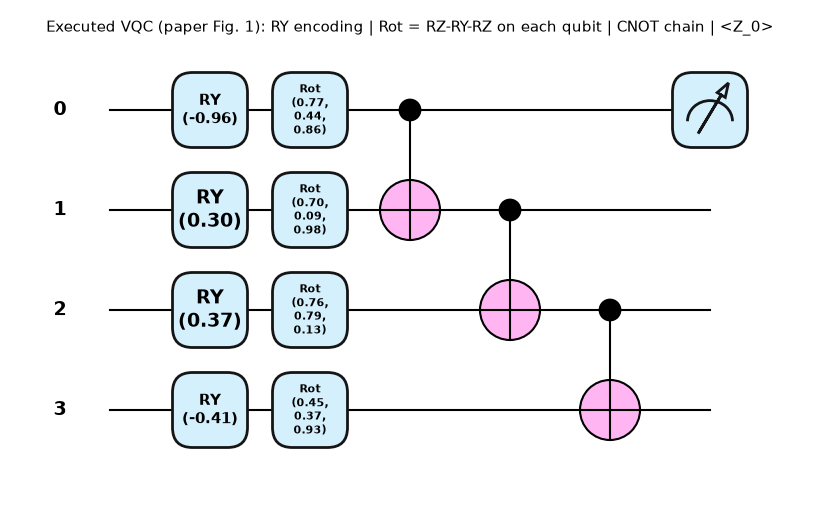

qubits = 4 | depth (after decomposing to device gates) = 5 | gate counts = {'RY': 4, 'Rot': 4, 'CNOT': 3}
trainable parameters = 12 (1 layer x 4 qubits x 3 angles); encoding angles are data, not parameters


In [12]:
x_demo = torch.tensor(D0["breast_cancer"]["Atr"][0]); p_demo = init_params(np.random.default_rng(SEED))
fig, ax = qml.draw_mpl(qnode, decimals=2, style="pennylane", fig_options=dict(figsize=(10, 4)))(p_demo, x_demo)
fig.suptitle("Executed VQC (paper Fig. 1): RY encoding | Rot = RZ-RY-RZ on each qubit | CNOT chain | <Z_0>", fontsize=11)
plt.show()
specs = qml.specs(qnode, level="device")(p_demo, x_demo)
res = specs.resources
print(f"qubits = {NQ} | depth (after decomposing to device gates) = {res.depth} | gate counts = {dict(res.gate_types)}")
print(f"trainable parameters = {p_demo.numel()} ({N_LAYERS} layer x {NQ} qubits x 3 angles); encoding angles are data, not parameters")

### Which parameters can the output actually depend on?

Pauli-Z on qubit 0 commutes with a CNOT whose **control** is qubit 0, and CNOT(1,2), CNOT(2,3) act on other qubits, so the whole CNOT chain leaves <Z_0> unchanged:
the circuit output only depends on `RY(x_0)` followed by `Rot` on qubit 0. The next cell verifies this numerically (exact zero gradient for the 9 angles on qubits 1 to 3, and equality with a one-qubit circuit).
This matters for the paper's claims that the VQC has "12 parameters" and that SQU's "unlearning parameter coverage is complete".

In [13]:
rng_t = np.random.default_rng(1)
dev1 = qml.device("default.qubit", wires=1)
@qml.qnode(dev1, interface="torch")
def one_qubit(rot, x0):
    qml.RY(x0, wires=0); qml.Rot(rot[0], rot[1], rot[2], wires=0)
    return qml.expval(qml.PauliZ(0))

max_dead_grad, max_diff = 0.0, 0.0
for _ in range(20):
    p = torch.tensor(rng_t.uniform(-np.pi, np.pi, (N_LAYERS, NQ, 3)), requires_grad=True); x = torch.tensor(rng_t.uniform(-np.pi / 2, np.pi / 2, (1, NQ)))
    out = vqc_forward(p, x)[0]; out.backward()
    max_dead_grad = max(max_dead_grad, p.grad[:, 1:, :].abs().max().item())
    max_diff = max(max_diff, abs(out.item() - one_qubit(p[0, 0].detach(), x[0, 0]).item()))
print(f"max |gradient| over the 9 angles on qubits 1-3 : {max_dead_grad:.1e}")
print(f"max |f(4-qubit circuit) - f(1-qubit circuit RY(x0), Rot)| : {max_diff:.1e}")
assert max_dead_grad < 1e-12 and max_diff < 1e-12
N_EFFECTIVE_PARAMS = 3
print(f"=> nominal parameters: {N_LAYERS * NQ * 3}; parameters that can change the output: {N_EFFECTIVE_PARAMS}; features that can reach the output: 1 (x_0, the first PCA component)")

max |gradient| over the 9 angles on qubits 1-3 : 2.7e-16
max |f(4-qubit circuit) - f(1-qubit circuit RY(x0), Rot)| : 4.4e-16
=> nominal parameters: 12; parameters that can change the output: 3; features that can reach the output: 1 (x_0, the first PCA component)


In [14]:
AUTHOR_OK = False
if USE_AUTHOR_REPO:
    try:
        repo_dir = os.path.join(DATA_DIR, "repos", "SQU")
        if not os.path.exists(repo_dir):
            os.makedirs(os.path.dirname(repo_dir), exist_ok=True)
            subprocess.run(["git", "clone", "-q", REPO_URL, repo_dir], check=True, timeout=300)
        subprocess.run(["git", "-C", repo_dir, "checkout", "-q", REPO_COMMIT], check=True, timeout=60)
        sys.path.insert(0, repo_dir)
        import quantum_classifier as author_qc          # the authors' PennyLane VQC (autograd interface)
        qc = author_qc.QuantumClassifier()
        qc.params = qml.numpy.array(p_demo.numpy(), requires_grad=True)       # same parameters as ours
        Xc = D0["breast_cancer"]["Atr"][:8]; yc = D0["breast_cancer"]["ytr"][:8]
        theirs = np.array([float(v) for v in qc.predict(Xc)])
        ours = vqc_forward(p_demo, torch.tensor(Xc)).numpy()
        d1 = np.abs(theirs - ours).max()
        # one gradient-descent step of THEIR optimiser on this batch versus OUR loss_and_grad update
        opt = qml.GradientDescentOptimizer(stepsize=LR)
        new_theirs, cost_theirs = opt.step_and_cost(lambda p: qc._cost(p, Xc, yc), qc.params)
        l_ours, g_ours = loss_and_grad(p_demo, torch.tensor(Xc), torch.tensor(2.0 * yc - 1))
        d2 = np.abs(np.array(new_theirs) - (p_demo - LR * g_ours).numpy()).max()
        print(f"authors' QuantumClassifier vs ours: max |f diff| = {d1:.2e}; one GD step: max |param diff| = {d2:.2e}; loss {float(cost_theirs):.6f} vs {l_ours:.6f}")
        assert d1 < 1e-9 and d2 < 1e-9
        AUTHOR_OK = True
    except Exception as e:
        print("Authors' repo cross-check skipped (needs git + network + their code importing):", type(e).__name__, str(e)[:200])

authors' QuantumClassifier vs ours: max |f diff| = 4.44e-16; one GD step: max |param diff| = 0.00e+00; loss 0.866680 vs 0.866680


## 4. Training, the attack and the unlearning methods

**Training** (Table II): plain gradient descent, learning rate 0.01, batches of 10, 20 epochs, mean squared error against labels in {-1, +1}.

**Membership inference attack.** Score = confidence |f(x)| of the VQC (for the classical NN: the largest softmax probability). Members = the forget samples (they were in the training set),
non-members = the whole test set. AUC of this score, reported as `max(AUC, 1 - AUC)`. Lower is better for privacy; 0.5 is random guessing.

**Unlearning treatments** (all start from the trained parameters theta*):

| name | what it does |
|---|---|
| `original` | no unlearning |
| `retrain` | fresh initialisation, 20 epochs on D_r only (gold standard) |
| `squ_code` | SQU as implemented by the authors: sensitivities, three tiers, budget proportional to the sensitivity, noise added per forget sample, 5 fine-tuning epochs |
| `squ_paper` | SQU as written in the paper: sigma_k = S_k / (eps max S) (Eq. 5), one Gaussian injection per forget sample, 10 fine-tuning epochs (Table II) |
| `static` | uniform tiny noise per forget sample, no fine-tuning |
| `simple_noise` | one N(0, 0.3^2) injection, no fine-tuning |
| `grad_ascent` | 5 gradient-ascent steps on the forget-set loss |

In [15]:
def mia_auc(f_members, f_nonmembers):
    """Effective MIA AUC max(AUC, 1-AUC) from confidence scores (members = 1)."""
    y = np.r_[np.ones(len(f_members)), np.zeros(len(f_nonmembers))]
    a = roc_auc_score(y, np.r_[f_members, f_nonmembers])
    return max(a, 1 - a)

def vqc_mia(params, Xf, Xte):
    return mia_auc(np.abs(predict_f(params, Xf).numpy()), np.abs(predict_f(params, Xte).numpy()))

def sensitivities(params, X, ypm):
    """S_k = || grad_theta loss(x_k, y_k) ||_2 for every forget sample (paper Eq. 4)."""
    return np.array([loss_and_grad(params, X[i:i + 1], ypm[i:i + 1])[1].norm().item() for i in range(len(X))])

def tiers_code(s):
    """Authors' rule: min-max normalise, High > 0.7, Medium > 0.3, else Low."""
    sn = (s - s.min()) / (s.max() - s.min()) if s.max() > s.min() else np.ones_like(s)
    return sn, np.where(sn > TIER_HIGH, 2, np.where(sn > TIER_MED, 1, 0))
def tiers_paper(s):
    """Paper Algorithm 1: High if S > mu + sigma, Low if S < mu - sigma, else Medium."""
    mu, sd = s.mean(), s.std()
    return np.where(s > mu + sd, 2, np.where(s < mu - sd, 0, 1))

def unlearn_squ_code(params, Xf, yf, Xr, yr, rng):
    s = sensitivities(params, Xf, yf); sn, tier = tiers_code(s)
    budgets = sn / (sn.sum() + 1e-8) * EPSILON
    p = params.clone()
    for b, t in zip(budgets, tier):
        level = b * (NOISE_HIGH if t == 2 else NOISE_MED if t == 1 else NOISE_LOW)
        p = p + torch.tensor(rng.normal(0, level, p.shape))
    p, _ = train_vqc(p, Xr, yr, FT_EPOCHS_CODE, rng)
    return p, s, tier

def unlearn_squ_paper(params, Xf, yf, Xr, yr, rng):
    s = sensitivities(params, Xf, yf)
    sigma = (1.0 / EPSILON) * s / s.max()                        # Eq. 5
    p = params.clone()
    for sg in sigma:                                             # Alg. 1 lines 10-12 / Eq. 6: aggregated variance sum_k sigma_k^2
        p = p + torch.tensor(rng.normal(0, sg, p.shape))
    p, _ = train_vqc(p, Xr, yr, FT_EPOCHS_PAPER, rng)
    return p, s, sigma

def unlearn_static(params, n_forget, rng):
    p = params.clone(); level = EPSILON / n_forget * NOISE_MED
    for _ in range(n_forget):
        p = p + torch.tensor(rng.normal(0, level, p.shape))
    return p

def unlearn_simple(params, rng):
    return params + torch.tensor(rng.normal(0, SIMPLE_STD, params.shape))

def unlearn_ascent(params, Xf, yf):
    p = params.clone()
    for _ in range(GA_STEPS):
        _, g = loss_and_grad(p, Xf, yf)
        p = p + GA_LR * g                                          # gradient ASCENT on the forget loss
    return p
print("unlearning functions defined")

unlearning functions defined


In [16]:
class ClassicalNN(nn.Module):
    """Paper Section V.B.4 / authors' classical_classifier.py: two hidden layers (64, 32), ReLU, dropout 0.2, 2 outputs."""
    def __init__(self, d_in):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_in, 64), nn.ReLU(), nn.Dropout(0.2), nn.Linear(64, 32), nn.ReLU(), nn.Dropout(0.2), nn.Linear(32, 2))
    def forward(self, x):
        return self.net(x)

def train_nn(Xtr, ytr, epochs, seed):
    torch.manual_seed(seed)
    X = torch.tensor(Xtr, dtype=torch.float32); y = torch.tensor(ytr, dtype=torch.long)
    model = ClassicalNN(X.shape[1]).float(); opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    g = torch.Generator().manual_seed(seed); hist = []
    for _ in range(epochs):
        model.train(); order = torch.randperm(len(X), generator=g); tot, nb = 0.0, 0
        for i in range(0, len(X), 32):
            idx = order[i:i + 32]; opt.zero_grad()
            loss = F.cross_entropy(model(X[idx]), y[idx]); loss.backward(); opt.step(); tot += loss.item(); nb += 1
        hist.append(tot / nb)
    model.eval()
    return model, hist

@torch.no_grad()
def nn_proba(model, X):
    return F.softmax(model(torch.tensor(X, dtype=torch.float32)), 1).numpy()
def nn_stats(model, Xtr, Xte, yte, fi):
    acc = float((nn_proba(model, Xte).argmax(1) == yte).mean())
    auc = mia_auc(nn_proba(model, Xtr[fi]).max(1), nn_proba(model, Xte).max(1))
    return acc, auc
print("classical NN parameters on 4 inputs:", sum(p.numel() for p in ClassicalNN(4).parameters()), "| on 30 inputs:", sum(p.numel() for p in ClassicalNN(30).parameters()), "| on 784 inputs:", sum(p.numel() for p in ClassicalNN(784).parameters()))

classical NN parameters on 4 inputs: 2466 | on 30 inputs: 4130 | on 784 inputs: 52386


## 5. The experiment loop

For every dataset and every seed: draw the data, train the VQC on the full training split, choose the forget set (the same random training samples for every method), apply all treatments to the same
trained parameters, and record test accuracy and the MIA AUC (forget samples versus test samples). The classical NN is trained and attacked in the same way (it is not unlearned: the paper only uses it for context).
Breast Cancer is also run with `N_FORGET_ALT` = 10 forget samples (the value of Table II).

In [17]:
def run_one(name, seed, n_forget, keep_extras=False):
    d = prepare(name, seed)
    rng = np.random.default_rng(seed)
    Xtr, Xte = torch.tensor(d["Atr"]), torch.tensor(d["Ate"])
    ytr_pm, ytr, yte = torch.tensor(2.0 * d["ytr"] - 1), torch.tensor(d["ytr"]), torch.tensor(d["yte"])
    fi = np.random.default_rng(seed + 10_000).choice(len(Xtr), n_forget, replace=False)
    keep = np.ones(len(Xtr), bool); keep[fi] = False
    Xf, yf, Xr, yr = Xtr[fi], ytr_pm[fi], Xtr[keep], ytr_pm[keep]
    rows, extras = [], {}
    def rec(method, params, **kw):
        rows.append(dict(dataset=name, seed=seed, n_forget=n_forget, method=method, acc=accuracy(params, Xte, yte),
                         auc=vqc_mia(params, Xf, Xte), acc_forget=accuracy(params, Xf, ytr[fi]), **kw))
    t0 = time.perf_counter()
    p_star, hist = train_vqc(init_params(rng), Xtr, ytr_pm, EPOCHS, rng)
    t_train = time.perf_counter() - t0
    rec("original", p_star, time_s=t_train, final_loss=hist[-1])
    t0 = time.perf_counter(); p_ret, hist_ret = train_vqc(init_params(rng), Xr, yr, EPOCHS, rng); rec("retrain", p_ret, time_s=time.perf_counter() - t0)
    t0 = time.perf_counter(); p_sc, s, tier_c = unlearn_squ_code(p_star, Xf, yf, Xr, yr, rng); rec("squ_code", p_sc, time_s=time.perf_counter() - t0)
    t0 = time.perf_counter(); p_sp, _, sigma = unlearn_squ_paper(p_star, Xf, yf, Xr, yr, rng); rec("squ_paper", p_sp, time_s=time.perf_counter() - t0)
    rec("static", unlearn_static(p_star, n_forget, rng), time_s=0.0)
    rec("simple_noise", unlearn_simple(p_star, rng), time_s=0.0)
    rec("grad_ascent", unlearn_ascent(p_star, Xf, yf), time_s=0.0)
    # classical NN baselines: not unlearned, only trained and attacked (same forget samples, same test set)
    for tag, Xa, Xb in (("pca4", d["Atr"], d["Ate"]), ("full", d["Str"], d["Ste"])):
        for ep in NN_EPOCHS:
            m, h = train_nn(Xa, d["ytr"], ep, seed)
            acc, auc = nn_stats(m, Xa, Xb, d["yte"], fi)
            rows.append(dict(dataset=name, seed=seed, n_forget=n_forget, method=f"nn_{tag}_e{ep}", acc=acc, auc=auc, acc_forget=np.nan, time_s=np.nan))
            if keep_extras and ep == NN_EPOCHS[0]:
                extras[f"nn_{tag}_hist"] = h
    if keep_extras:
        extras.update(vqc_hist=hist, s=s, tier_code=tier_c, tier_paper=tiers_paper(s), sigma=sigma, p_star=p_star, fi=fi,
                      params=dict(original=p_star, retrain=p_ret, squ_code=p_sc, squ_paper=p_sp))
    return rows, extras

t_all = time.perf_counter()
ROWS, EXTRAS = [], {}
for nm in DATASETS:
    t0 = time.perf_counter()
    for r in range(N_SEEDS):
        rows, ex = run_one(nm, SEED + r, N_FORGET, keep_extras=(r == 0))
        ROWS += rows
        if r == 0: EXTRAS[nm] = ex
    print(f"{nm:14s}: {N_SEEDS} seeds done in {time.perf_counter() - t0:6.1f} s")
t0 = time.perf_counter()
for r in range(N_SEEDS):
    rows, _ = run_one("breast_cancer", SEED + r, N_FORGET_ALT); ROWS += rows
print(f"breast_cancer with {N_FORGET_ALT} forget samples: {N_SEEDS} seeds in {time.perf_counter() - t0:.1f} s")
RES = pd.DataFrame(ROWS)
print(f"all runs finished in {(time.perf_counter() - t_all) / 60:.1f} min; {len(RES)} result rows")

breast_cancer : 20 seeds done in  498.1 s


mnist         : 20 seeds done in 1361.6 s


fashion_mnist : 20 seeds done in 1183.9 s


breast_cancer with 10 forget samples: 20 seeds in 424.1 s
all runs finished in 57.8 min; 880 result rows


## 6. Results

### 6.0 Replay of the authors' own run (seed 42, three datasets): does their code give the paper's numbers?
The paper's tables are one run. The authors' `run_experiments.py` seeds numpy once (`np.random.seed(42)`) and then draws everything from numpy's *global* random state, in a fixed order: the data subsample, PCA (for the image sets), the forget set,
the initial angles (building a PennyLane device before drawing them also consumes numbers!), the mini-batch shuffles, the noise. The next cell replays that exact sequence with our simulator (whose output, gradients and one
training step were shown above to equal the authors' own class) for Breast Cancer, MNIST and Fashion-MNIST in that order. Pre-processing is fitted on all samples before the split here, because this is the authors' protocol; everywhere else in this notebook it is fitted on the training split only.

For Breast Cancer the authors' own `run_single_experiment` was also executed once in this environment (pinned commit, seed 42, about 12 minutes on a shared CPU); its printed values are recorded in `AUTHOR_CODE_BC` below and the replay must reproduce them. Set `RUN_AUTHOR_CODE = True`
in the configuration cell to run it again yourself.

In [18]:
def _legacy_train(params, X, ypm, epochs, lr=LR, batch=BATCH):
    """Authors' `QuantumClassifier.train`: shuffling with numpy's legacy GLOBAL random state (np.random.permutation)."""
    params = params.clone(); hist = []
    for _ in range(epochs):
        order = np.random.permutation(len(X)); tot, nb = 0.0, 0
        for i in range(0, len(X), batch):
            idx = order[i:i + batch]
            l, g = loss_and_grad(params, X[idx], ypm[idx])
            params = params - lr * g; tot += l; nb += 1
        hist.append(tot / nb)
    return params, hist

def _legacy_params():
    """`QuantumClassifier()`: building a PennyLane device already consumes numbers from numpy's global random state, then the angles are drawn."""
    qml.device("default.qubit", wires=NQ)
    return torch.tensor(np.random.random((N_LAYERS, NQ, 3)))

def replay_authors_run(datasets=DATASETS):
    """Re-run the authors' `run_experiments.py` (seed 42, the three datasets in their order) with our simulator. The random numbers are drawn
    in exactly the order of the authors' code (data subsample, PCA, forget set, initial angles, shuffles, noise), so a faithful simulator must give
    the same numbers as their code. As in their code, the pre-processing is fitted on ALL samples before the split."""
    np.random.seed(42)                                                   # config.py: np.random.seed(RANDOM_SEED)
    out = {}
    for name in datasets:
        X, y = POOL[name]
        idx = np.random.choice(len(X), min(N_SAMPLES[name], len(X)), replace=False)
        Xs, ys = X[idx].astype(float), y[idx]
        Z = PCA(n_components=min(N_QUBITS, Xs.shape[1])).fit_transform(StandardScaler().fit_transform(Xs))      # random_state=None: may consume the global RNG
        A = np.pi * (Z - Z.min()) / (Z.max() - Z.min() + 1e-8) - np.pi / 2
        Xtr, Xte, ytr, yte = train_test_split(A, ys, test_size=0.3, random_state=42, stratify=ys)
        n_forget = min(15, len(Xtr) // 4)
        fi = np.random.choice(len(Xtr), size=n_forget, replace=False)
        keep = np.ones(len(Xtr), bool); keep[fi] = False
        Xtr_t, Xte_t = torch.tensor(Xtr), torch.tensor(Xte); ytr_pm = torch.tensor(2.0 * ytr - 1); yte_t = torch.tensor(yte)
        Xf, yf, Xr, yr = Xtr_t[fi], ytr_pm[fi], Xtr_t[keep], ytr_pm[keep]
        res = {}
        def rec(m, p):
            res[m] = dict(acc=accuracy(p, Xte_t, yte_t), auc=vqc_mia(p, Xf, Xte_t))
        p_star, hist = _legacy_train(_legacy_params(), Xtr_t, ytr_pm, EPOCHS); rec("original", p_star)
        # SQU (authors' recipe), same random-number order as `SQU.unlearn`
        _legacy_params()                                                 # `qc_squ = QuantumClassifier()` consumes numbers that are then overwritten
        s = sensitivities(p_star, Xf, yf); sn, tier = tiers_code(s); budgets = sn / (sn.sum() + 1e-8) * EPSILON
        p = p_star.clone()
        for b, t in zip(budgets, tier):
            p = p + torch.tensor(np.random.normal(0, b * (NOISE_HIGH if t == 2 else NOISE_MED if t == 1 else NOISE_LOW), p.shape))
        p, _ = _legacy_train(p, Xr, yr, FT_EPOCHS_CODE); rec("squ_code", p)
        _legacy_params()                                                 # qc_static
        p = p_star.clone()
        for _ in range(n_forget):
            p = p + torch.tensor(np.random.normal(0, EPSILON / n_forget * NOISE_MED, p.shape))
        rec("static", p)
        _legacy_params()                                                 # qc_simple
        rec("simple_noise", p_star + torch.tensor(np.random.normal(0, SIMPLE_STD, p_star.shape)))
        _legacy_params()                                                 # qc_gradascent
        rec("grad_ascent", unlearn_ascent(p_star, Xf, yf))
        p_ret, _ = _legacy_train(_legacy_params(), Xr, yr, EPOCHS); rec("retrain", p_ret)
        res["meta"] = dict(n_train=len(Xtr), n_test=len(Xte), n_forget=n_forget, final_loss=hist[-1], hist=hist, tiers=tuple(int((tier == t).sum()) for t in (2, 1, 0)), sens=s)
        out[name] = res
    return out

t0 = time.perf_counter()
REPLAY = replay_authors_run()
print(f"replay of the authors' run finished in {time.perf_counter() - t0:.0f} s")
for nm in DATASETS:
    r_ = REPLAY[nm]; m_ = r_["meta"]
    print(f"\n{nm}: {m_['n_train']} train / {m_['n_test']} test / {m_['n_forget']} forget | final training loss {m_['final_loss']:.4f} | tiers High/Medium/Low = {m_['tiers']}")
    print(pd.DataFrame({k: v for k, v in r_.items() if k != "meta"}).T.reindex(["original", "retrain", "squ_code", "static", "simple_noise", "grad_ascent"]).round(4).to_string())

replay of the authors' run finished in 63 s

breast_cancer: 210 train / 90 test / 15 forget | final training loss 0.3615 | tiers High/Medium/Low = (4, 4, 7)
                 acc     auc
original      0.8444  0.6548
retrain       0.8444  0.6541
squ_code      0.8444  0.6481
static        0.8333  0.6422
simple_noise  0.8333  0.6356
grad_ascent   0.8444  0.6504

mnist: 560 train / 240 test / 15 forget | final training loss 0.2146 | tiers High/Medium/Low = (1, 4, 10)
                 acc     auc
original      0.9792  0.5300
retrain       0.9792  0.5272
squ_code      0.9792  0.5300
static        0.9917  0.6019
simple_noise  0.8208  0.5622
grad_ascent   0.9792  0.5261

fashion_mnist: 560 train / 240 test / 15 forget | final training loss 0.7143 | tiers High/Medium/Low = (4, 2, 9)
                 acc     auc
original      0.7917  0.6078
retrain       0.7917  0.6078
squ_code      0.7917  0.6086
static        0.8292  0.6239
simple_noise  0.7750  0.5889
grad_ascent   0.7917  0.6072


In [19]:
# Values printed by the authors' own code (`run_experiments.run_single_experiment("breast_cancer")` after np.random.seed(42), pinned commit, executed once in this environment)
AUTHOR_CODE_BC = dict(original=(0.8444, 0.6548), squ_code=(0.8444, 0.6481), static=(0.8333, 0.6422), retrain=(0.8444, 0.6541), final_loss=0.3615, tiers=(4, 4, 7))
rp = REPLAY["breast_cancer"]
rows_ = []
for m_ in ("original", "squ_code", "static", "retrain"):
    rows_.append(dict(method=m_, acc_authors_code=AUTHOR_CODE_BC[m_][0], acc_replay=round(rp[m_]["acc"], 4), auc_authors_code=AUTHOR_CODE_BC[m_][1], auc_replay=round(rp[m_]["auc"], 4)))
print(pd.DataFrame(rows_).to_string(index=False))
print("final training loss: authors' code", AUTHOR_CODE_BC["final_loss"], "| replay", round(rp["meta"]["final_loss"], 4), "| tiers High/Medium/Low: authors' code", AUTHOR_CODE_BC["tiers"], "| replay", rp["meta"]["tiers"])
REPLAY_MATCH = all(abs(AUTHOR_CODE_BC[m_][0] - rp[m_]["acc"]) < 6e-4 and abs(AUTHOR_CODE_BC[m_][1] - rp[m_]["auc"]) < 6e-4 for m_ in ("original", "squ_code", "static", "retrain")) \
    and abs(AUTHOR_CODE_BC["final_loss"] - rp["meta"]["final_loss"]) < 6e-4 and tuple(AUTHOR_CODE_BC["tiers"]) == tuple(rp["meta"]["tiers"])
print("replay reproduces the authors' own code on Breast Cancer:", REPLAY_MATCH)
if RUN_AUTHOR_CODE and AUTHOR_OK:                  # optional: run the authors' code itself (slow: PennyLane autograd, one QNode call per sample)
    import config as author_config; author_config.VERBOSE = False
    import run_experiments as author_run
    np.random.seed(42)
    res_a, hist_a = author_run.run_single_experiment("breast_cancer")
    print({k: round(float(res_a[k]), 4) for k in ("acc_before", "acc_after_squ", "acc_after_static", "acc_after_retrain", "attack_before", "attack_after_squ", "attack_after_static", "attack_after_retrain")}, "final loss", round(hist_a[-1], 4))
else:
    print("RUN_AUTHOR_CODE is False: the authors' code was not re-run in this execution (set it to True to do so; about 10 minutes).")

  method  acc_authors_code  acc_replay  auc_authors_code  auc_replay
original            0.8444      0.8444            0.6548      0.6548
squ_code            0.8444      0.8444            0.6481      0.6481
  static            0.8333      0.8333            0.6422      0.6422
 retrain            0.8444      0.8444            0.6541      0.6541
final training loss: authors' code 0.3615 | replay 0.3615 | tiers High/Medium/Low: authors' code (4, 4, 7) | replay (4, 4, 7)
replay reproduces the authors' own code on Breast Cancer: True
RUN_AUTHOR_CODE is False: the authors' code was not re-run in this execution (set it to True to do so; about 10 minutes).


### 6.1 Training convergence (paper Fig. 5)
The VQC curve is the replay of the authors' run (Breast Cancer, 210 training samples); the classical NN curves come from our own training of the NN (cross-entropy, so the two panels are on different scales, as in the paper).

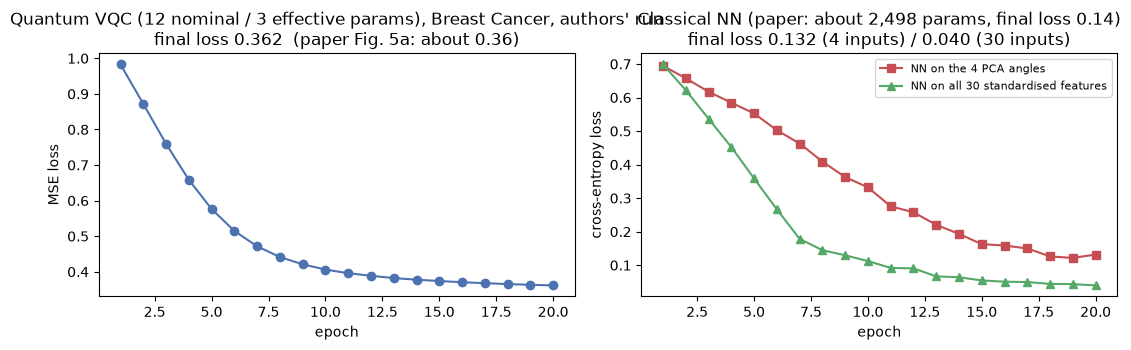

In [20]:
ex = EXTRAS["breast_cancer"]; hv = REPLAY["breast_cancer"]["meta"]["hist"] if "hist" in REPLAY["breast_cancer"]["meta"] else ex["vqc_hist"]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(range(1, EPOCHS + 1), hv, "o-", color="#4C72B0")
ax[0].set_title(f"Quantum VQC ({N_LAYERS * NQ * 3} nominal / {N_EFFECTIVE_PARAMS} effective params), Breast Cancer, authors' run\nfinal loss {hv[-1]:.3f}  (paper Fig. 5a: about 0.36)")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("MSE loss")
ax[1].plot(range(1, NN_EPOCHS[0] + 1), ex["nn_pca4_hist"], "s-", color="#C44E52", label="NN on the 4 PCA angles")
ax[1].plot(range(1, NN_EPOCHS[0] + 1), ex["nn_full_hist"], "^-", color="#55A868", label="NN on all 30 standardised features")
ax[1].set_title(f"Classical NN (paper: about 2,498 params, final loss 0.14)\nfinal loss {ex['nn_pca4_hist'][-1]:.3f} (4 inputs) / {ex['nn_full_hist'][-1]:.3f} (30 inputs)")
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("cross-entropy loss"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

### 6.2 Table III redrawn: accuracy, MIA AUC and privacy gain, mean +- std over seeds
"Privacy gain" is the paper's column: MIA AUC before unlearning minus MIA AUC after, in AUC points x 100 (positive = the attacker became weaker).

In [21]:
MAIN = RES[RES.n_forget == N_FORGET]
base = MAIN[MAIN.method == "original"][["dataset", "seed", "auc", "acc"]].rename(columns={"auc": "auc0", "acc": "acc0"})
R2 = MAIN.merge(base, on=["dataset", "seed"]); R2["gain"] = (R2.auc0 - R2.auc) * 100
ORDER = ["original", "retrain", "squ_code", "squ_paper", "static", "simple_noise", "grad_ascent"]
def table(df, cols=("acc", "auc", "gain")):
    out = {}
    for nm in DATASETS:
        g = df[df.dataset == nm].groupby("method")
        out[nm] = pd.DataFrame({
            "test acc %": (g.acc.mean() * 100).round(1).astype(str) + " +- " + (g.acc.std() * 100).round(1).astype(str),
            "median acc %": (g.acc.median() * 100).round(1),
            "MIA AUC": g.auc.mean().round(3).astype(str) + " +- " + g.auc.std().round(3).astype(str),
            "privacy gain": g.gain.mean().round(2).astype(str) + " +- " + g.gain.std().round(2).astype(str)}).reindex(ORDER)
    return out
TAB = table(R2)
for nm in DATASETS:
    print(f"\n{nm}  ({N_SEEDS} seeds, {N_FORGET} forget samples; test set {len(D0[nm]['yte'])} samples)")
    print(TAB[nm].to_string())


breast_cancer  (20 seeds, 15 forget samples; test set 90 samples)
               test acc %  median acc %         MIA AUC   privacy gain
method                                                                
original      90.1 +- 2.1          90.0  0.548 +- 0.039     0.0 +- 0.0
retrain       90.0 +- 1.9          90.0  0.547 +- 0.038     0.1 +- 0.7
squ_code      90.1 +- 2.0          90.0   0.547 +- 0.04   0.12 +- 0.75
squ_paper     87.7 +- 6.7          88.9  0.542 +- 0.031   0.58 +- 2.14
static        88.4 +- 4.1          87.8  0.554 +- 0.037  -0.58 +- 1.19
simple_noise  85.9 +- 7.8          87.2  0.547 +- 0.029   0.04 +- 3.07
grad_ascent   90.0 +- 1.8          90.0  0.548 +- 0.039   -0.0 +- 0.51

mnist  (20 seeds, 15 forget samples; test set 240 samples)
                test acc %  median acc %         MIA AUC   privacy gain
method                                                                 
original       98.5 +- 1.1          98.8  0.565 +- 0.045     0.0 +- 0.0
retrain        98.

In [22]:
# The paper's single run: the first seed, shown on its own (the paper's numbers are one split).
first = R2[(R2.seed == SEED) & R2.method.isin(ORDER)].pivot(index="method", columns="dataset", values=["acc", "auc", "gain"]).reindex(ORDER)
print(f"Run 0 only (seed {SEED}); acc as fraction, MIA AUC, privacy gain in AUC points x 100")
print(first.round(3).to_string())

Run 0 only (seed 42); acc as fraction, MIA AUC, privacy gain in AUC points x 100
                       acc                                auc                               gain                     
dataset      breast_cancer fashion_mnist  mnist breast_cancer fashion_mnist  mnist breast_cancer fashion_mnist  mnist
method                                                                                                               
original             0.878         0.850  0.988         0.523         0.541  0.591         0.000         0.000  0.000
retrain              0.878         0.854  0.988         0.523         0.546  0.582         0.000        -0.500  0.806
squ_code             0.878         0.833  0.983         0.521         0.534  0.593         0.222         0.667 -0.278
squ_paper            0.878         0.854  0.988         0.525         0.546  0.590        -0.222        -0.500  0.056
static               0.833         0.838  0.988         0.526         0.538  0.585        -0.

### 6.3 Figure 4 redrawn
**Replay of the authors' run (one run, like the paper).** Bars: our replay; black diamonds: the values printed in the paper's Fig. 4 (two decimals; the figure has no "Before" accuracy bar). Panel (c) is the replay's sensitivity-tier count (paper: 4 / 4 / 7).

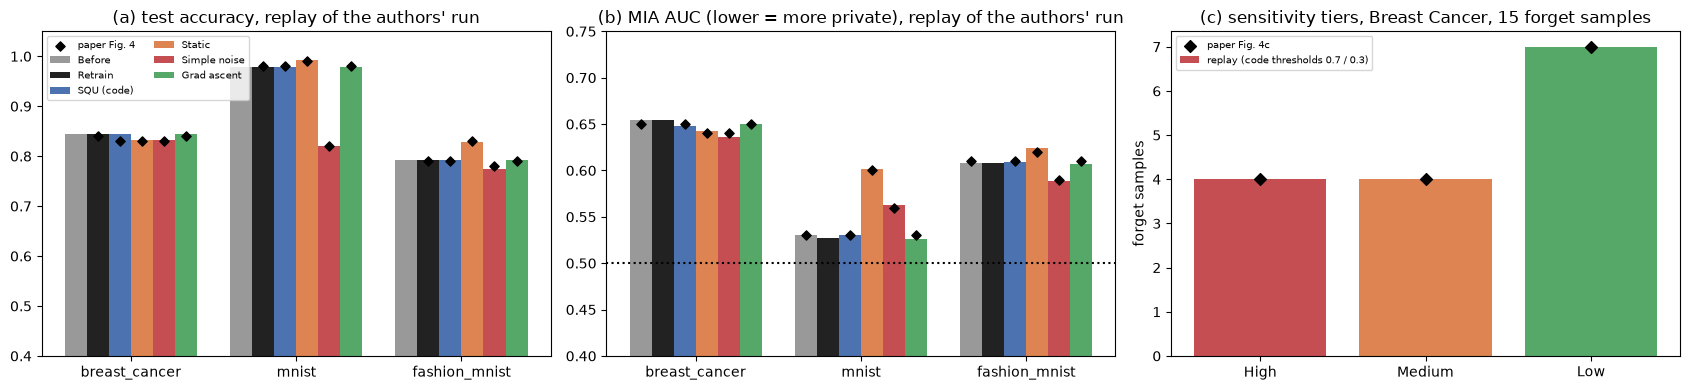

largest difference between the replay and the numbers printed in Fig. 4: accuracy 0.014, MIA AUC 0.005 (the figure shows two decimals)
Breast Cancer replay sensitivities S_k (sorted): [2.272 2.139 1.998 1.814 1.696 1.687 1.184 1.136 0.71  0.698 0.666 0.657
 0.63  0.518 0.464]


In [23]:
labels = {"original": "Before", "retrain": "Retrain", "squ_code": "SQU (code)", "squ_paper": "SQU (Eq. 5)", "static": "Static", "simple_noise": "Simple noise", "grad_ascent": "Grad ascent"}
cols = dict(original="#999999", retrain="#222222", squ_code="#4C72B0", squ_paper="#8172B3", static="#DD8452", simple_noise="#C44E52", grad_ascent="#55A868")
# values printed in the paper's Fig. 4 (order: Breast Cancer, MNIST, Fashion-MNIST)
FIG4_ACC = dict(retrain=[0.84, 0.98, 0.79], squ_code=[0.83, 0.98, 0.79], static=[0.83, 0.99, 0.83], simple_noise=[0.83, 0.82, 0.78], grad_ascent=[0.84, 0.98, 0.79])
FIG4_AUC = dict(original=[0.65, 0.53, 0.61], squ_code=[0.65, 0.53, 0.61], static=[0.64, 0.60, 0.62], simple_noise=[0.64, 0.56, 0.59], grad_ascent=[0.65, 0.53, 0.61])
RMETH = ["original", "retrain", "squ_code", "static", "simple_noise", "grad_ascent"]
fig, ax = plt.subplots(1, 3, figsize=(17, 4)); w = 0.8 / len(RMETH)
for k, m in enumerate(RMETH):
    off = (k - len(RMETH) / 2 + 0.5) * w
    ax[0].bar(np.arange(3) + off, [REPLAY[nm][m]["acc"] for nm in DATASETS], w, color=cols[m], label=labels[m])
    ax[1].bar(np.arange(3) + off, [REPLAY[nm][m]["auc"] for nm in DATASETS], w, color=cols[m])
    if m in FIG4_ACC: ax[0].scatter(np.arange(3) + off, FIG4_ACC[m], marker="D", s=22, color="k", zorder=5, label="paper Fig. 4" if m == "retrain" else None)
    if m in FIG4_AUC: ax[1].scatter(np.arange(3) + off, FIG4_AUC[m], marker="D", s=22, color="k", zorder=5)
for a, ttl in ((ax[0], "(a) test accuracy"), (ax[1], "(b) MIA AUC (lower = more private)")):
    a.set_xticks(range(3)); a.set_xticklabels(DATASETS); a.set_title(ttl + ", replay of the authors' run")
ax[1].axhline(0.5, color="k", ls=":"); ax[0].set_ylim(0.4, 1.05); ax[1].set_ylim(0.4, 0.75); ax[0].legend(fontsize=7, ncol=2)
tc = REPLAY["breast_cancer"]["meta"]["tiers"]
ax[2].bar(np.arange(3), tc, color=["#C44E52", "#DD8452", "#55A868"], label="replay (code thresholds 0.7 / 0.3)")
ax[2].scatter(np.arange(3), [4, 4, 7], marker="D", color="k", zorder=5, label="paper Fig. 4c")
ax[2].set_xticks(range(3)); ax[2].set_xticklabels(["High", "Medium", "Low"]); ax[2].set_ylabel("forget samples"); ax[2].legend(fontsize=7)
ax[2].set_title("(c) sensitivity tiers, Breast Cancer, 15 forget samples")
plt.tight_layout(); plt.show()
def fig_gap(d, key):
    return max(abs(REPLAY[nm][m][key] - d[m][i]) for m in d for i, nm in enumerate(DATASETS))
FIG4_ACC_GAP, FIG4_AUC_GAP = fig_gap(FIG4_ACC, "acc"), fig_gap(FIG4_AUC, "auc")
print(f"largest difference between the replay and the numbers printed in Fig. 4: accuracy {FIG4_ACC_GAP:.3f}, MIA AUC {FIG4_AUC_GAP:.3f} (the figure shows two decimals)")
print("Breast Cancer replay sensitivities S_k (sorted):", np.round(np.sort(REPLAY["breast_cancer"]["meta"]["sens"])[::-1], 3))

**Many seeds (mean and standard deviation over `N_SEEDS` independent runs, clean pre-processing).** The same two panels, but now each bar is an average over independent data draws, splits, forget sets and initialisations.

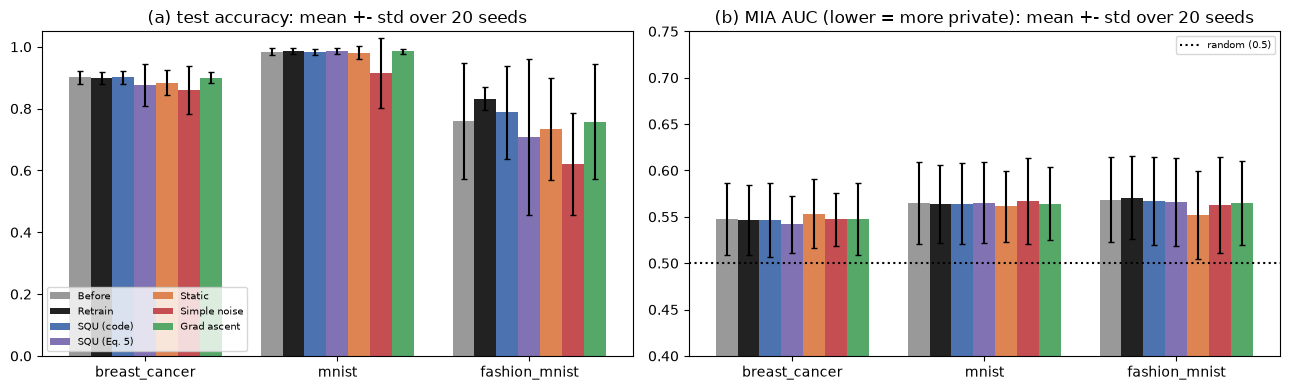

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4)); w = 0.8 / len(ORDER)
for k, m in enumerate(ORDER):
    for a, key in ((ax[0], "acc"), (ax[1], "auc")):
        mu = [MAIN[(MAIN.dataset == nm) & (MAIN.method == m)][key].mean() for nm in DATASETS]
        sd = [MAIN[(MAIN.dataset == nm) & (MAIN.method == m)][key].std() for nm in DATASETS]
        a.bar(np.arange(3) + (k - len(ORDER) / 2 + 0.5) * w, mu, w, yerr=sd, capsize=2, color=cols[m], label=labels[m] if key == "acc" else None)
for a, ttl in ((ax[0], "(a) test accuracy"), (ax[1], "(b) MIA AUC (lower = more private)")):
    a.set_xticks(range(3)); a.set_xticklabels(DATASETS); a.set_title(f"{ttl}: mean +- std over {N_SEEDS} seeds")
ax[1].axhline(0.5, color="k", ls=":", label="random (0.5)"); ax[0].legend(fontsize=7, ncol=2); ax[1].legend(fontsize=7)
ax[0].set_ylim(0.0, 1.05); ax[1].set_ylim(0.4, 0.75)
plt.tight_layout(); plt.show()

### 6.4 Classical neural network versus VQC (paper Table IV)

In [25]:
cls = MAIN[MAIN.method.str.startswith("nn_") | (MAIN.method == "original")]
t4 = []
for nm in DATASETS:
    for m, lab in (("original", "Quantum VQC"), ("nn_pca4_e20", "NN, 4 PCA inputs, 20 ep"), ("nn_full_e20", "NN, all features, 20 ep"), ("nn_full_e50", "NN, all features, 50 ep")):
        g = cls[(cls.dataset == nm) & (cls.method == m)]
        t4.append(dict(dataset=nm, model=lab, acc=f"{100*g.acc.mean():.1f} +- {100*g.acc.std():.1f}", mia_auc=f"{g.auc.mean():.3f} +- {g.auc.std():.3f}"))
print(pd.DataFrame(t4).to_string(index=False))
print("\nTrainable parameters: VQC 12 nominal / 3 effective | NN on 4 inputs", sum(p.numel() for p in ClassicalNN(4).parameters()), "| NN on 30 inputs", sum(p.numel() for p in ClassicalNN(30).parameters()))

      dataset                   model          acc        mia_auc
breast_cancer             Quantum VQC  90.1 +- 2.1 0.548 +- 0.039
breast_cancer NN, 4 PCA inputs, 20 ep  95.4 +- 2.2 0.555 +- 0.046
breast_cancer NN, all features, 20 ep  97.2 +- 1.5 0.562 +- 0.039
breast_cancer NN, all features, 50 ep  97.2 +- 1.3 0.553 +- 0.040
        mnist             Quantum VQC  98.5 +- 1.1 0.565 +- 0.045
        mnist NN, 4 PCA inputs, 20 ep  99.7 +- 0.4 0.570 +- 0.052
        mnist NN, all features, 20 ep  99.6 +- 0.4 0.558 +- 0.049
        mnist NN, all features, 50 ep  99.6 +- 0.4 0.551 +- 0.036
fashion_mnist             Quantum VQC 76.0 +- 18.7 0.568 +- 0.046
fashion_mnist NN, 4 PCA inputs, 20 ep  95.1 +- 1.6 0.545 +- 0.031
fashion_mnist NN, all features, 20 ep  98.3 +- 0.6 0.557 +- 0.038
fashion_mnist NN, all features, 50 ep  98.1 +- 0.9 0.547 +- 0.030

Trainable parameters: VQC 12 nominal / 3 effective | NN on 4 inputs 2466 | NN on 30 inputs 4130


### 6.5 Is any difference between methods larger than the seed-to-seed noise?
For each dataset and treatment: the mean privacy gain and a paired t-test against zero over the seeds (a gain is "significant" only if p < 0.05). Also the robustness run with 10 forget samples (Table II's value) on Breast Cancer.

In [26]:
rows = []
for nm in DATASETS:
    for m in ["retrain", "squ_code", "squ_paper", "static", "simple_noise", "grad_ascent"]:
        g = R2[(R2.dataset == nm) & (R2.method == m)].gain.values
        t, p = stats.ttest_1samp(g, 0.0) if len(g) > 2 and g.std() > 0 else (np.nan, np.nan)
        rows.append(dict(dataset=nm, method=m, mean_gain=g.mean(), std=g.std(), p_value=p, significant=("yes" if p < 0.05 else "no")))
sig = pd.DataFrame(rows); print(sig.round(3).to_string(index=False))
ALT = RES[(RES.n_forget == N_FORGET_ALT) & (RES.dataset == "breast_cancer") & RES.method.isin(ORDER)]
print(f"\nBreast Cancer with {N_FORGET_ALT} forget samples (Table II value), mean over {N_SEEDS} seeds:")
print(ALT.groupby("method")[["acc", "auc"]].mean().reindex(ORDER).round(3).to_string())

      dataset       method  mean_gain   std  p_value significant
breast_cancer      retrain      0.100 0.680    0.529          no
breast_cancer     squ_code      0.122 0.734    0.477          no
breast_cancer    squ_paper      0.581 2.086    0.239          no
breast_cancer       static     -0.581 1.158    0.041         yes
breast_cancer simple_noise      0.037 2.991    0.958          no
breast_cancer  grad_ascent     -0.004 0.494    0.974          no
        mnist      retrain      0.126 0.970    0.577          no
        mnist     squ_code      0.057 0.606    0.687          no
        mnist    squ_paper     -0.053 0.694    0.744          no
        mnist       static      0.362 4.917    0.751          no
        mnist simple_noise     -0.182 5.525    0.887          no
        mnist  grad_ascent      0.079 1.367    0.803          no
fashion_mnist      retrain     -0.224 1.965    0.625          no
fashion_mnist     squ_code      0.150 0.711    0.370          no
fashion_mnist    squ_pape

### 6.6 Why does the accuracy vary so much between seeds? (per-seed diagnosis)
Plain gradient descent with learning rate 0.01 for 20 epochs is a very small training budget for angles initialised in [0, 1). The output is a single smooth function of the first angle, and the optimiser can end in a poor basin:
a final loss above 1 means the model is worse than predicting 0 for everybody, and an accuracy below 50 % means its decision is inverted. The table lists, for each seed, the test accuracy of the original model next to its final training loss.

In [27]:
orig = MAIN[MAIN.method == "original"].pivot(index="seed", columns="dataset", values=["acc", "final_loss"])
print("original VQC: test accuracy (left) and final training MSE (right) per seed")
print(orig.round(3).to_string())
for nm in DATASETS:
    g = MAIN[(MAIN.method == "original") & (MAIN.dataset == nm)]
    rho = stats.spearmanr(g.final_loss, g.acc)[0] if g.acc.nunique() > 1 else float("nan")
    print(f"{nm:14s}: Spearman correlation between final training loss and test accuracy over seeds = {rho:+.2f}")

original VQC: test accuracy (left) and final training MSE (right) per seed
                  acc                         final_loss                     
dataset breast_cancer fashion_mnist  mnist breast_cancer fashion_mnist  mnist
seed                                                                         
42              0.878         0.850  0.988         0.413         0.743  0.213
43              0.922         0.842  0.988         0.445         0.818  0.264
44              0.922         0.229  0.988         0.435         1.227  0.279
45              0.900         0.729  0.983         0.468         0.765  0.266
46              0.878         0.867  0.979         0.401         0.729  0.332
47              0.922         0.817  1.000         0.382         0.658  0.253
48              0.911         0.842  0.979         0.456         0.730  0.281
49              0.933         0.829  0.950         0.384         0.658  0.413
50              0.889         0.833  0.983         0.489         0.

### 6.7 Does fitting the pre-processing on all samples (as the authors' code does) explain the accuracy gap on Breast Cancer?
The authors' code standardises, applies PCA and fixes the angle range on all 300 samples *before* the train/test split. We re-train only the original model on Breast Cancer with that leaky pipeline and compare it with the clean one used everywhere else.

In [28]:
def prepare_leaky(name, seed):
    rng = np.random.default_rng(seed); X, y = POOL[name]
    sel = rng.choice(len(X), min(N_SAMPLES[name], len(X)), replace=False); Xs, ys = X[sel].astype(float), y[sel]
    Z = PCA(N_QUBITS, random_state=seed).fit_transform(StandardScaler().fit_transform(Xs))          # fitted on ALL samples (authors' code)
    A = np.pi * (Z - Z.min()) / (Z.max() - Z.min() + 1e-8) - np.pi / 2
    return train_test_split(A, ys, test_size=TEST_SIZE, random_state=seed, stratify=ys)
leaky_acc = []
for r in range(N_SEEDS):
    Atr, Ate, ytr, yte = prepare_leaky("breast_cancer", SEED + r)
    rr = np.random.default_rng(SEED + r)
    p_, _ = train_vqc(init_params(rr), torch.tensor(Atr), torch.tensor(2.0 * ytr - 1), EPOCHS, rr)
    leaky_acc.append(accuracy(p_, torch.tensor(Ate), torch.tensor(yte)))
clean_acc = MAIN[(MAIN.method == "original") & (MAIN.dataset == "breast_cancer")].acc.values
print(f"Breast Cancer, original VQC, {N_SEEDS} seeds: clean pre-processing {100*clean_acc.mean():.1f} +- {100*clean_acc.std():.1f} %  |  leaky (authors' code) {100*np.mean(leaky_acc):.1f} +- {100*np.std(leaky_acc):.1f} %  |  paper 84.4 %")

Breast Cancer, original VQC, 20 seeds: clean pre-processing 90.1 +- 2.1 %  |  leaky (authors' code) 89.9 +- 1.6 %  |  paper 84.4 %


## 7. Side by side with the paper: a verdict per claim
Rule (as in the other notebooks of this repository): a number is **reproduced** if it is within 2 accuracy points (or 0.02 MIA AUC, or 2 gain points) of the paper's value; otherwise **not reached** or **exceeded** (with the gap; for MIA AUC "exceeded" means *lower*, i.e. more private, than the paper).
Two verdicts per row: **replay** = the authors' own run (seed 42), which is what the paper reports; **seeds** = the mean over `N_SEEDS` independent runs with train-only pre-processing, which says whether the paper's number is typical. A dash means the quantity does not exist in that mode.

In [29]:
def S(ds, m, key):   # mean over seeds
    return float(MAIN[(MAIN.dataset == ds) & (MAIN.method == m)][key].mean())
def G(ds, m):
    return float(R2[(R2.dataset == ds) & (R2.method == m)].gain.mean())
def RPV(ds, m, key):
    return float(REPLAY[ds][m][key])
def RPG(ds, m):
    return (RPV(ds, "original", "auc") - RPV(ds, m, "auc")) * 100

V = []
def _v(paper, ours, tol, higher_better):
    if ours is None: return "-"
    gap = ours - paper
    if abs(gap) <= tol: return "reproduced"
    return ("exceeded" if gap > 0 else "not reached") if higher_better else ("exceeded" if gap < 0 else "not reached")
def claim(what, paper, rep, seeds, tol, higher_better=True, unit="", fmt=".4g", note=""):
    V.append(dict(claim=what, paper=f"{paper:g}{unit}", replay="-" if rep is None else f"{rep:{fmt}}{unit}", verdict_replay=_v(paper, rep, tol, higher_better),
                  seeds="-" if seeds is None else f"{seeds:{fmt}}{unit}", verdict_seeds=_v(paper, seeds, tol, higher_better), note=note))
def qual(what, paper_stmt, rep_stmt, rep_ok, seeds_stmt, seeds_ok):
    V.append(dict(claim=what, paper=paper_stmt, replay=rep_stmt if rep_stmt else "-", verdict_replay="-" if rep_ok is None else ("reproduced" if rep_ok else "not reached"),
                  seeds=seeds_stmt if seeds_stmt else "-", verdict_seeds="-" if seeds_ok is None else ("reproduced" if seeds_ok else "not reached"), note=""))

names = {"breast_cancer": "Breast Cancer", "mnist": "MNIST", "fashion_mnist": "Fashion-MNIST"}
P = dict(retrain_acc=dict(breast_cancer=84.4, mnist=97.9, fashion_mnist=79.2), squ_acc=dict(breast_cancer=83.3, mnist=97.9, fashion_mnist=79.2),
         retrain_auc=dict(breast_cancer=0.654, mnist=0.527, fashion_mnist=0.608), squ_auc=dict(breast_cancer=0.648, mnist=0.530, fashion_mnist=0.609),
         squ_gain=dict(breast_cancer=0.67, mnist=0.00, fashion_mnist=-0.08), static_gain=dict(breast_cancer=0.07, mnist=-7.19, fashion_mnist=-1.61))
for ds in DATASETS:
    claim(f"{names[ds]}: retrain accuracy (Table III)", P["retrain_acc"][ds], 100 * RPV(ds, "retrain", "acc"), 100 * S(ds, "retrain", "acc"), 2, unit=" %", fmt=".1f")
for ds in DATASETS:
    claim(f"{names[ds]}: SQU accuracy, authors' recipe (Table III)", P["squ_acc"][ds], 100 * RPV(ds, "squ_code", "acc"), 100 * S(ds, "squ_code", "acc"), 2, unit=" %", fmt=".1f")
for ds in DATASETS:
    claim(f"{names[ds]}: SQU accuracy, paper Eq. 5 recipe", P["squ_acc"][ds], None, 100 * S(ds, "squ_paper", "acc"), 2, unit=" %", fmt=".1f")
for ds in DATASETS:
    claim(f"{names[ds]}: MIA AUC of retrain (Table III)", P["retrain_auc"][ds], RPV(ds, "retrain", "auc"), S(ds, "retrain", "auc"), 0.02, higher_better=False, fmt=".3f")
for ds in DATASETS:
    claim(f"{names[ds]}: MIA AUC of SQU, authors' recipe (Table III)", P["squ_auc"][ds], RPV(ds, "squ_code", "auc"), S(ds, "squ_code", "auc"), 0.02, higher_better=False, fmt=".3f")
for ds in DATASETS:
    claim(f"{names[ds]}: privacy gain of SQU, authors' recipe (Table III)", P["squ_gain"][ds], RPG(ds, "squ_code"), G(ds, "squ_code"), 2, unit=" pts", fmt="+.2f")
for ds in DATASETS:
    claim(f"{names[ds]}: privacy gain of static unlearning (Table III)", P["static_gain"][ds], RPG(ds, "static"), G(ds, "static"), 2, unit=" pts", fmt="+.2f")
claim("Fig. 4a: all 15 accuracy bars (largest gap to the printed 2-decimal values)", 0.0, FIG4_ACC_GAP, float(np.nanmax([abs(S(nm, m, "acc") - FIG4_ACC[m][i]) for m in FIG4_ACC for i, nm in enumerate(DATASETS)])), 0.02, higher_better=False, fmt=".3f", note="gap, not a score")
claim("Fig. 4b: all 15 MIA AUC bars (largest gap to the printed 2-decimal values)", 0.0, FIG4_AUC_GAP, float(np.nanmax([abs(S(nm, m, "auc") - FIG4_AUC[m][i]) for m in FIG4_AUC for i, nm in enumerate(DATASETS)])), 0.02, higher_better=False, fmt=".3f", note="gap, not a score")
claim("Breast Cancer: VQC test accuracy before unlearning (Fig. 5a, Table IV)", 84.4, 100 * RPV("breast_cancer", "original", "acc"), 100 * S("breast_cancer", "original", "acc"), 2, unit=" %", fmt=".1f")
claim("Breast Cancer: VQC MIA AUC before unlearning (Table IV)", 0.654, RPV("breast_cancer", "original", "auc"), S("breast_cancer", "original", "auc"), 0.02, higher_better=False, fmt=".3f")
claim("Breast Cancer: classical NN accuracy, 4 PCA inputs, 20 epochs (Table IV: 94.4)", 94.4, None, 100 * S("breast_cancer", "nn_pca4_e20", "acc"), 2, unit=" %", fmt=".1f")
claim("Breast Cancer: classical NN accuracy, all features, 20 epochs (Table IV: 94.4)", 94.4, None, 100 * S("breast_cancer", "nn_full_e20", "acc"), 2, unit=" %", fmt=".1f")
claim("Breast Cancer: classical NN MIA AUC, all features, 50 epochs (Table IV: 0.555)", 0.555, None, S("breast_cancer", "nn_full_e50", "auc"), 0.02, higher_better=False, fmt=".3f")
claim("Breast Cancer: VQC final training loss after 20 epochs (Fig. 5a)", 0.36, REPLAY["breast_cancer"]["meta"]["final_loss"], float(MAIN[(MAIN.method == "original") & (MAIN.dataset == "breast_cancer")].final_loss.mean()), 0.05, higher_better=False, fmt=".3f")
claim("Breast Cancer: classical NN final loss after 20 epochs (Fig. 5b)", 0.14, None, EXTRAS["breast_cancer"]["nn_pca4_hist"][-1], 0.05, higher_better=False, fmt=".3f", note="4-input NN, one run")
V.append(dict(claim="Breast Cancer: forget-sample tiers High/Medium/Low (Fig. 4c)", paper="4 / 4 / 7", replay=" / ".join(map(str, REPLAY["breast_cancer"]["meta"]["tiers"])),
              verdict_replay="reproduced" if REPLAY["breast_cancer"]["meta"]["tiers"] == (4, 4, 7) else "not reached", seeds="depends on the forget set", verdict_seeds="-", note=""))
claim("VQC trainable parameters (Table IV)", 12, float(N_LAYERS * NQ * 3), float(N_LAYERS * NQ * 3), 0, fmt=".0f", note=f"but only {N_EFFECTIVE_PARAMS} can change the output (circuit section)")

# qualitative claims
gap_r = {ds: abs(RPV(ds, "squ_code", "acc") - RPV(ds, "retrain", "acc")) * 100 for ds in DATASETS}
gap_s = {ds: abs(S(ds, "squ_code", "acc") - S(ds, "retrain", "acc")) * 100 for ds in DATASETS}
qual("SQU (authors' recipe) matches retrain accuracy within 2 points on every dataset", "within 1.1 points", "gaps " + ", ".join(f"{names[d]} {v:.1f}" for d, v in gap_r.items()), all(v <= 2 for v in gap_r.values()),
     "gaps " + ", ".join(f"{names[d]} {v:.1f}" for d, v in gap_s.items()), all(v <= 2 for v in gap_s.values()))
gap_p = {ds: abs(S(ds, "squ_paper", "acc") - S(ds, "retrain", "acc")) * 100 for ds in DATASETS}
qual("SQU (paper Eq. 5 recipe) matches retrain accuracy within 2 points on every dataset", "within 1.1 points", None, None, "gaps " + ", ".join(f"{names[d]} {v:.1f}" for d, v in gap_p.items()), all(v <= 2 for v in gap_p.values()))
qual("SQU does not degrade privacy on MNIST as static noise does (SQU gain >= static gain)", "SQU 0.00 vs static -7.19", f"SQU {RPG('mnist','squ_code'):+.2f} vs static {RPG('mnist','static'):+.2f}", RPG("mnist", "squ_code") >= RPG("mnist", "static"),
     f"SQU {G('mnist','squ_code'):+.2f} vs static {G('mnist','static'):+.2f}", G("mnist", "squ_code") >= G("mnist", "static") + 2)
sq = sig[(sig.method == "squ_code") & (sig.dataset == "breast_cancer")].iloc[0]
qual("SQU gives a measurable privacy gain on Breast Cancer (> 0; over seeds: significantly > 0)", "+0.67 points", f"{RPG('breast_cancer','squ_code'):+.2f} points (one run)", RPG("breast_cancer", "squ_code") > 0,
     f"{G('breast_cancer','squ_code'):+.2f} points, p = {sq.p_value:.2f}", bool(sq.significant == "yes" and G("breast_cancer", "squ_code") > 0))
qual("Classical NN is more accurate than the VQC on Breast Cancer", "94.4 vs 84.4 %", None, None, f"{100*S('breast_cancer','nn_full_e20','acc'):.1f} vs {100*S('breast_cancer','original','acc'):.1f} %", S("breast_cancer", "nn_full_e20", "acc") > S("breast_cancer", "original", "acc"))
qual("Classical NN leaks less than the VQC on Breast Cancer (lower MIA AUC)", "0.555 vs 0.654", None, None, f"{S('breast_cancer','nn_full_e50','auc'):.3f} vs {S('breast_cancer','original','auc'):.3f} (std {MAIN[(MAIN.dataset=='breast_cancer')&(MAIN.method=='original')].auc.std():.3f})",
     S("breast_cancer", "nn_full_e50", "auc") < S("breast_cancer", "original", "auc") - MAIN[(MAIN.dataset == "breast_cancer") & (MAIN.method == "original")].auc.std())
qual("'Complete' parameter coverage: all 12 VQC parameters take part in the sensitivity analysis", "12 of 12 parameters", f"{N_EFFECTIVE_PARAMS} of 12 can change the output", False, f"{N_EFFECTIVE_PARAMS} of 12 can change the output", False)
VT = pd.DataFrame(V)
pd.set_option("display.width", 300, "display.max_colwidth", 80)
print(VT.to_string(index=False))
print("\nreplay verdict counts:", VT.verdict_replay.value_counts().to_dict())
print("seeds  verdict counts:", VT.verdict_seeds.value_counts().to_dict())

                                                                                     claim                    paper                                               replay verdict_replay                                                 seeds verdict_seeds                                               note
                                               Breast Cancer: retrain accuracy (Table III)                   84.4 %                                               84.4 %     reproduced                                                90.0 %      exceeded                                                   
                                                       MNIST: retrain accuracy (Table III)                   97.9 %                                               97.9 %     reproduced                                                98.5 %    reproduced                                                   
                                               Fashion-MNIST: retrain accuracy (Table III) 

## 8. Reading the paper critically

**What reproduces.** Replaying the authors' own run (section 6.0) gives their Table III and Fig. 4 almost exactly: accuracy 84.4 / 97.9 / 79.2 % for the retrained model, MIA AUC 0.654 / 0.527 / 0.608, SQU gains +0.67 / 0.00 / -0.08 points,
static-noise gains -7.19 (MNIST) and -1.61 (Fashion-MNIST), the 4 / 4 / 7 sensitivity tiers and the final loss 0.36. The numbers in the paper are therefore the deterministic output of the public code with `np.random.seed(42)`, not an invented or tuned table.
Two printed values differ from that run by about one point (inside the 2-point tolerance, but visibly different): the SQU accuracy on Breast Cancer (the code gives 84.4 %, the table prints 83.3 %) and the static-noise gain on Breast Cancer (the code gives about +1.3 points, the table prints +0.07).

**What one run can and cannot say.**
* It is **one** draw: one 300-sample subsample, one split, one forget set of 15 samples, one initialisation. The multi-seed tables (sections 6.2 to 6.6) show how far a typical run lies from it: Breast Cancer accuracy and MIA AUC of the original model, and especially the very uneven
  Fashion-MNIST accuracy (some seeds finish with a loss above 1 and an accuracy below 50 %, i.e. stuck on the wrong side after 20 epochs of plain gradient descent at lr 0.01), differ from the single published run by more than its two printed decimals suggest.
* The "membership" being attacked is only 15 forget samples against a test set. A confidence-based AUC computed from 15 members has a standard error of several AUC points, as large as the published gains (+0.67, 0.00, -0.08) and losses (-7.19, -1.61):
  the paired tests in section 6.5 show whether any gain stands out from noise. A -7 point swing on MNIST from static noise of standard deviation 0.023 rad per injection is a property of this one draw, not of "uniform noise".
* The MIA AUC of the original model is already equal to the AUC of the retrained model, and the retrained model never saw the forget samples. The attack therefore measures how *typical* a sample is (confident predictions on easy points),
  not whether it was memorised. A model with effectively three parameters cannot memorise 15 particular samples, so there is almost nothing to forget and almost no leakage to remove.
* "Retrain from scratch" is evaluated with the same forget samples and the same attack, so the "gold standard" has an AUC of about 0.65 too; matching it is not evidence that information was removed.
* SQU with the authors' hyper-parameters moves the angles by about 0.1 rad in total and fine-tunes with learning rate 0.01, so its accuracy and AUC equal those of the original model: "SQU matches retraining" is true because nothing changed.

**Structural finding about the circuit.** With the CNOT chain placed after the rotations and the measurement on qubit 0 (control of CNOT(0,1)), the output equals the one-qubit circuit `RY(x_0)`, `Rot`: only 3 of the 12
parameters and only the first PCA coordinate matter (verified in the circuit section; the other 9 gradients are exactly 0). The claims "12-parameter VQC", "complete parameter coverage" and "exact sensitivity analysis over every parameter" are therefore
true in letter but not in substance, and the VQC-versus-NN comparison is really a one-feature, one-qubit model against a multi-feature network.

**Eq. 5 versus the code.** Taken literally, sigma_k = S_k / (eps max S) puts noise with standard deviation up to 1 rad on every angle for each forget sample, and with 15 samples the aggregated standard deviation is about 2 rad:
that lowers the mean accuracy and strongly increases its spread, because 10 fine-tuning epochs of plain gradient descent at lr 0.01 cannot always repair it (see the `squ_paper` rows in section 6.2: Breast Cancer 87.7 +- 6.7 %, Fashion-MNIST 70.8 +- 25.3 %). The authors' code uses budgets that sum to eps and tier factors 0.2 to 0.5, i.e. per-sample noise of about 0.01 to 0.03 rad;
the paper's tables were evidently produced by that code. No (epsilon, delta) differential-privacy guarantee is established (the authors say so in Section VI), so "adhering to differential privacy principles" is a design motivation, not a property.

**Other caveats.** (1) The authors' code standardises, applies PCA and fixes the angle range on all samples before the train/test split, which leaks test information (section 6.7 measures how little it changes the accuracy); the multi-seed runs fit on the training split only. (2) The paper never says that MNIST and Fashion-MNIST are
reduced to two classes (0 vs 1, T-shirt vs trouser); this is visible only in the code (a single Pauli-Z expectation value cannot separate ten classes). (3) Table II (10 forget samples, 200 retained) and Fig. 4c / the code (15 forget samples) disagree.
(4) Everything is noiseless simulation; the claim that hardware noise "can even aid unlearning" is not tested.

## 9. Exercises
1. **Move the measurement or the CNOTs.** Put the CNOT chain *before* the rotations, or run it as CNOT(i+1, i), or add a closing CNOT(3, 0). Re-run the gradient check of the circuit section: how many parameters now matter and how does the Breast Cancer accuracy change?
2. **Stronger attack.** Replace the confidence score by the per-sample loss (needs the label) or by a shadow-model attack, and use all training samples (not just 15) as members. Does the original model leak more than the retrained one?
3. **Make the budgets meaningful.** Sweep the noise scale of `squ_code` over 0.01 to 1 rad and plot accuracy against MIA AUC for SQU, static and simple noise. Is there a regime in which SQU is better than uniform noise at the same accuracy?
4. **Forget a whole class or the most influential points.** Choose the forget set as the 15 samples with the largest sensitivity (or one whole class) instead of random samples. Does retraining now differ from the original model, and does SQU follow retraining?
5. **Certified unlearning.** The paper leaves (epsilon, delta)-DP open. Using the Gaussian mechanism, how large must the noise be for epsilon = 1, delta = 1e-5 given the sensitivity values printed above, and what is the accuracy afterwards?